# AI-generated reference solution (earlier version of the task), NOT part of our submission

This notebook was produced by an AI coding agent (Claude Code) on 28.10.2026, before the project day. Dominic commissioned it as a reference; none of us wrote or edited its content. Our own work and our submission will live in the project notebook(s) in the repository root.

**It solves the earlier version of the task.** On 29.10. neue fische changed the project; before, there were 330 photos, no `data/validation` folder and eight steps. Therefore:

- **Other photos for training and validation.** It uses the same photo files in `data/train` and `data/test` as we do, but it trains on only 240 of the 300 training photos: it holds back 60 of them as its own validation set (`validation_split=0.2`, seed 42), and those 60 belong to our training set. The 60 photos in `data/validation` are not used. Its test results refer to the same 30 test photos, but come from models trained on 240 photos, and its validation numbers are not comparable with ours.
- **Models:** a chance baseline (`DummyClassifier`), a CNN from scratch, a comparison of two pretrained bases (MobileNetV2 and EfficientNetB0), a logistic regression on the frozen features, a dense head with and without augmentation, fine-tuning and a Keras Tuner search. The current task asks only for the dense head, with augmentation if needed. The notebook saves no model, so it covers neither step 5 (save every model) nor step 7 (the app).
- **Limits from the agent's own brief, not from the course:** at most 160 × 160 pixels, a 60-minute time budget, at most 10 Keras Tuner trials, the format of `ergebnis.json` and the notes to the "Auftraggeber" (whoever ordered the analysis). Where the text says that the course requires something, it means the earlier task.
- **It does not run in this repository as it is.** The first code cell imports `keras_tuner`, which the current project no longer installs. The second code cell looks for an `auftrag/` folder, reads the photos from `auftrag/data/` and writes to `arbeit/` and `abgabe/`.
- **Language:** explanations, printed output, plot labels and table headers are in German; code and code comments are in English.
- **Written after the test:** the "Was wir sehen" texts and the conclusion were finalised after the test set had been evaluated once. Code and outputs were not changed afterwards.
- **Removed from the original:** one closing section with an internal checklist of the agent's working procedure. Apart from that and the kernel entry in the notebook metadata, nothing was changed.

Do not copy code or decisions from here into the submission without understanding and re-deriving them. Suggestion: open it only after we have chosen our own model in step 5, so that our decisions stay our own. A second reference that solves the current version of the task, in English, is being prepared and will be added next to this one.

# Blumenfotos erkennen: Rose, Sonnenblume oder Tulpe?

**Frage.** Ein Gartencenter will, dass ein Modell aus einem hochgeladenen Foto die richtige Pflegeanleitung wählt: Rose,
Sonnenblume oder Tulpe. Wir haben nur 100 Trainingsfotos je Blume. Wir prüfen, wie weit ein vortrainiertes Netz (Transfer
Learning) einen CNN schlägt, der von Grund auf lernt, was Augmentation, Fine-Tuning und eine Suche mit Keras Tuner bringen,
und **bei welchen Fotos das beste Modell danebenliegt**.

**Art der Frage:** Vorhersage (Klassifikation). **Zielgröße:** die Blume im Foto, drei Klassen. **Anwendungszeitpunkt:** in
dem Moment, in dem ein Kunde ein Foto hochlädt; das Modell sieht dann nur das Foto, sonst nichts.

**Eine Zeile ist ein Foto.** Die unabhängige Einheit ist eigentlich nicht ganz das Foto: Mehrere Fotos stammen vom selben
Flickr-Fotografen und zeigen oft denselben Garten oder dieselbe Serie. Das prüfen wir in Schritt 3 mit `data/LICENSE.txt`.
Es gibt 330 Fotos: 300 in `data/train`, 30 in `data/test`.

Das Notebook folgt den **acht Schritten der Kursaufgabe** in ihrer Reihenfolge. Vor jeder Codezelle steht, **was** sie tut,
**welche Entscheidung** fällt, **warum**, und welche **Alternative** wir verworfen haben. Nach jeder Ausgabe steht
**„Was wir sehen“**.

### Vorbereitung: Bibliotheken und Seeds

**Was:** Wir laden die Bibliotheken des Kurses und legen Pfade fest. Über den Kurs hinaus brauchen wir nur zwei Dinge:
`scipy.stats` (kommt mit scikit-learn mit) für exakte Binomial-Intervalle und `StratifiedKFold` aus scikit-learn für eine
Kreuzvalidierung auf den Merkmalen. Beides erklären wir, wenn es vorkommt.

**Entscheidung:** Ein Seed (`42`) für alles, gesetzt mit `keras.utils.set_random_seed`; er setzt Python, NumPy und
TensorFlow zugleich. Wir setzen ihn vor jedem Training neu, damit jedes Modell für sich reproduzierbar ist, egal in welcher
Reihenfolge die Zellen laufen.

**Was trotzdem zufällig bleibt:** TensorFlow rechnet auf der CPU mit mehreren Threads; die Reihenfolge, in der Teilsummen
addiert werden, schwankt, und damit die Gewichte in den letzten Stellen. Nach vielen Epochen kann das eine Vorhersage kippen
lassen, die knapp an einer Grenze liegt. **Alternative:** `tf.config.experimental.enable_op_determinism()` erzwingt
bitgleiche Läufe, macht das Training aber langsamer; bei unserem 60-Minuten-Rahmen verzichten wir darauf und sagen es hier.

TensorFlow meldet beim Start, dass es keine Grafikkarte (CUDA) findet; das ist auf diesem Laptop erwartet und harmlos.
Zwei sich wiederholende Hinweise von Keras blenden wir aus (`warnings.filterwarnings`, Standardbibliothek).

Gespeichert wird nichts im Projektordner des Kurses: Keras-Tuner-Dateien und Zwischenstände gehen nach `arbeit/`, die
Ergebnisse nach `abgabe/`.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info messages

import hashlib
import json
import platform
import time
from collections import Counter
from pathlib import Path

import keras
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import tensorflow as tf
import warnings
from keras.applications import efficientnet, mobilenet_v2
from PIL import Image
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score

I0000 00:00:1793202713.547783  437938 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793202713.549248  437938 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793202715.983349  437938 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793202715.986024  437938 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


**Was wir sehen:** Die Importe laufen ohne Fehler. TensorFlow meldet auf Englisch, dass es keine CUDA-Treiber (Grafikkarte)
findet und auf der CPU rechnet; das ist auf diesem Laptop erwartet.

**Was die nächste Zelle tut:** Sie sucht den Projektordner (den Ordner, in dem `auftrag/` liegt), legt die Pfade für Daten,
Arbeitsdateien und Abgabe an, setzt den Seed und zeigt die Paketversionen. **Entscheidung:** Pfade relativ zum
Projektordner. **Verworfen:** ein fester absoluter Pfad; dann liefe das Notebook nur auf diesem einen Rechner.

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "auftrag").is_dir())  # project folder
DATA = ROOT / "auftrag" / "data"
WORK = ROOT / "arbeit"
OUT = ROOT / "abgabe"
(OUT / "fehler").mkdir(parents=True, exist_ok=True)

# Two harmless Keras notices that would repeat in every training cell
warnings.filterwarnings("ignore", message=".*shuffle=True.*")
warnings.filterwarnings("ignore", message=".*Skipping variable loading for optimizer.*")

SEED = 42
keras.utils.set_random_seed(SEED)
T0 = time.time()
pd.DataFrame({"Paket": ["python", "tensorflow", "keras", "keras_tuner", "scikit-learn", "scipy", "numpy", "pandas"],
              "Version": [platform.python_version(), tf.__version__, keras.__version__, kt.__version__,
                          sklearn.__version__, scipy.__version__, np.__version__, pd.__version__]})

,Paket,Version
0,python,3.13.16
1,tensorflow,2.21.0
2,keras,3.15.1
3,keras_tuner,1.4.8
4,scikit-learn,1.9.1
5,scipy,1.18.1
6,numpy,2.5.4
7,pandas,3.1.0


**Was wir sehen:** Python 3.13.16, TensorFlow 2.21.0, Keras 3.15.1, Keras Tuner 1.4.8, scikit-learn 1.9.1: genau die
Umgebung aus `uv.lock` des Kurses. Wer das Notebook nachrechnet, sollte dieselben Versionen nutzen, sonst können sich die
Zahlen in den letzten Stellen unterscheiden.

## Schritt 1: Ziel und Metrik festlegen

**Was:** Bevor wir ein einziges Modell trainieren, legen wir fest, woran wir Modelle messen, wann das Projekt ein Erfolg
ist und nach welcher Regel wir das beste Modell wählen. Sonst könnten wir die Regel nachträglich so legen, dass unser
Lieblingsmodell gewinnt.

**Sind die Klassen gleich häufig?** Das zeigt die Abbildung unten: Wir zählen nur die Dateien in den Ordnern von
`data/train`. Den Ordner `data/test` öffnen wir nicht; laut Datenbeschreibung liegen dort je 10 Fotos.

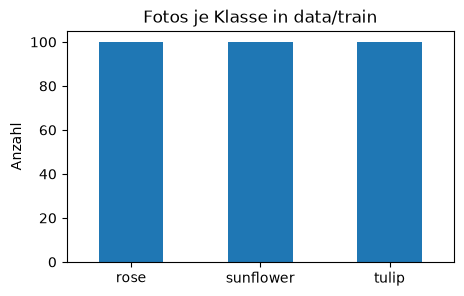

,rose,sunflower,tulip
Fotos,100,100,100


In [3]:
classes = sorted(p.name for p in (DATA / "train").iterdir() if p.is_dir())
train_counts = pd.Series({c: len(list((DATA / "train" / c).glob("*.jpg"))) for c in classes}, name="Fotos")
ax = train_counts.plot.bar(rot=0, figsize=(5, 3), title="Fotos je Klasse in data/train")
ax.set_ylabel("Anzahl")
plt.show()
train_counts.to_frame().T

**Was wir sehen:** In `data/train` liegen je **100** Fotos für Rose, Sonnenblume und Tulpe; die Klassen sind exakt gleich
groß. Daraus folgt die Wahl der Metrik unten.

**Entscheidung Metrik: Genauigkeit (Accuracy)**, also der Anteil richtig eingeordneter Fotos. Sie ist leicht zu erklären
(„9 von 10 Kunden bekommen die richtige Anleitung“) und bei gleich großen Klassen nicht irreführend: Wer immer dieselbe
Klasse rät, kommt nur auf etwa ein Drittel.

- **Verworfen: F1 (Makro).** Sinnvoll bei ungleichen Klassen; bei 100/100/100 sagt sie fast dasselbe wie die Genauigkeit,
  ist aber schwerer zu erklären.
- **Verworfen: Log-Loss als Hauptmetrik.** Er misst, wie gut die Wahrscheinlichkeiten sind, und reagiert feiner als die
  Genauigkeit. Für das Gartencenter zählt aber, ob die Anleitung stimmt. Wir nutzen den Validierungs-Loss nur als Hilfsgröße
  (für `EarlyStopping` und Keras Tuner), weil er bei nur 60 Validierungsfotos weniger Gleichstände hat.

Eine Zahl reicht dem Gartencenter nicht. Deshalb gehören zum Ergebnis eine **Konfusionsmatrix** (welche Blumen werden
verwechselt?) und die **Wahrscheinlichkeiten** (merkt das Modell, wenn es unsicher ist?).

**Auswahlregel (fest, bevor ein Modell trainiert ist).** Wir wählen das Modell mit der höchsten Validierungsgenauigkeit,
wie im Kurs verlangt. Liegen mehrere Modelle **höchstens ein Validierungsfoto** (1/60 ≈ 1,7 Prozentpunkte) unter dem
besten, nehmen wir unter ihnen das **einfachste**: das mit den wenigsten trainierbaren Parametern, bei Gleichstand das mit
weniger Trainingsstufen (logistische Regression vor Dense-Kopf vor Augmentation). Warum diese Toleranz? Bei 60 Fotos und
etwa 95 % Genauigkeit beträgt der Standardfehler √(0,95·0,05/60) ≈ 2,8 Prozentpunkte, also etwa 1,7 Fotos. Ein Foto
Unterschied ist damit Rauschen (eine abgeschwächte Ein-Standardfehler-Regel). **Verworfen:** stur das Maximum nehmen; dann
gewinnt bei Gleichstand der Zufall, und ein kompliziertes Modell, das auf denselben 60 Fotos ausgesucht wurde, sieht besser
aus, als es ist. Dieselbe Regel gilt innerhalb jeder Stufe (CNN-Variante, Fine-Tuning-Variante).

**Erfolgskriterium (fest, bevor ein Modell trainiert ist), geprüft auf den 30 Testfotos:**

| | Bedingung |
|---|---|
| K1 | Das gewählte Modell schlägt die Zufallsbaseline: das gepaarte 95-%-Bootstrap-Intervall der Differenz (je Foto richtig/falsch) liegt ganz über 0. |
| K2 | Das gewählte Modell schlägt den CNN von Grund auf, im selben Sinn (Intervall ganz über 0). |
| K3 | Die Testgenauigkeit des gewählten Modells ist mindestens 0,90 (höchstens 3 von 30 Fotos falsch). |

Die Schwelle 0,90 in K3 haben wir selbst gesetzt (der Auftrag nennt keine): Bei einer schlechteren Quote müsste das
Personal so viele Fotos nachprüfen, dass sich die Automatik kaum lohnt. **Gegen entartete Lösungen geprüft:** Wer immer
dieselbe Blume sagt, trifft genau 10 von 30 (0,33) und verfehlt K1 und K3; keine Konstante kann das Kriterium erfüllen.

**Kann die Testmenge die Unterschiede überhaupt auflösen?** Ein Testfoto macht 3,3 Prozentpunkte aus. Bei 30 Fotos und
90 % Genauigkeit ist das 95-%-Intervall etwa ±11 Prozentpunkte breit. Große Sprünge (Zufall → Transfer Learning, CNN →
Transfer Learning) kann der Test zeigen, kleine Schritte (Augmentation, Fine-Tuning, Tuner, meist wenige Prozentpunkte)
**nicht**. Diese vergleichen wir deshalb nur auf der Validierung und sagen dazu, wie unsicher das ist.

In [4]:
SUCCESS_MIN_ACC = 0.90   # K3
STAFF_THRESHOLD = 0.8    # rule from the course: staff checks photos below this probability

## Schritt 2: Die Daten ansehen

**Was:** Wir schauen auf die Dateien von `data/train`: Größe, Farbmodus, Dubletten, und ein paar Fotos je Klasse. Das ist
reine Struktur, wir lernen hier noch nichts aus den Daten.

**Entscheidung:** Exakte Dubletten (byte-gleiche Dateien) würden wir vor dem Split entfernen, weil sonst dasselbe Foto in
Training und Validierung landen kann. **Alternative verworfen:** ähnliche Fotos schon hier per Auge suchen; das geht erst
sinnvoll mit den Merkmalen des vortrainierten Netzes (Schritt 6).

In [5]:
rows = []
for c in classes:
    for f in sorted((DATA / "train" / c).glob("*.jpg")):
        with Image.open(f) as im:
            rows.append({"klasse": c, "datei": f.name, "breite": im.size[0], "hoehe": im.size[1], "modus": im.mode,
                         "md5": hashlib.md5(f.read_bytes()).hexdigest()})
files = pd.DataFrame(rows)
print("Farbmodi:", dict(Counter(files["modus"])))
print("Exakte Dubletten (gleicher md5):", files["md5"].duplicated().sum())
files[["breite", "hoehe"]].describe().round(0).T

Farbmodi: {'RGB': 300}
Exakte Dubletten (gleicher md5): 0


,count,mean,std,min,25%,50%,75%,max
breite,300.0,381.0,116.0,159.0,320.0,320.0,500.0,640.0
hoehe,300.0,286.0,61.0,180.0,240.0,240.0,333.0,407.0


**Was wir sehen:** Alle 300 Fotos sind farbig (RGB) und lesbar, es gibt **keine** byte-gleichen Dubletten. Die Breite reicht
von 159 bis 640 Pixel (Median 320), die Höhe von 180 bis 407 Pixel (Median 240). Kein Foto ist kleiner als 160 Pixel in
der Höhe; nur wenige sind schmaler als 160 Pixel. Es gibt also nichts strukturell zu bereinigen.

**Ein paar Fotos je Klasse.** Wir zeigen je vier Originalfotos, unverändert, damit wir sehen, was das Modell leisten muss.

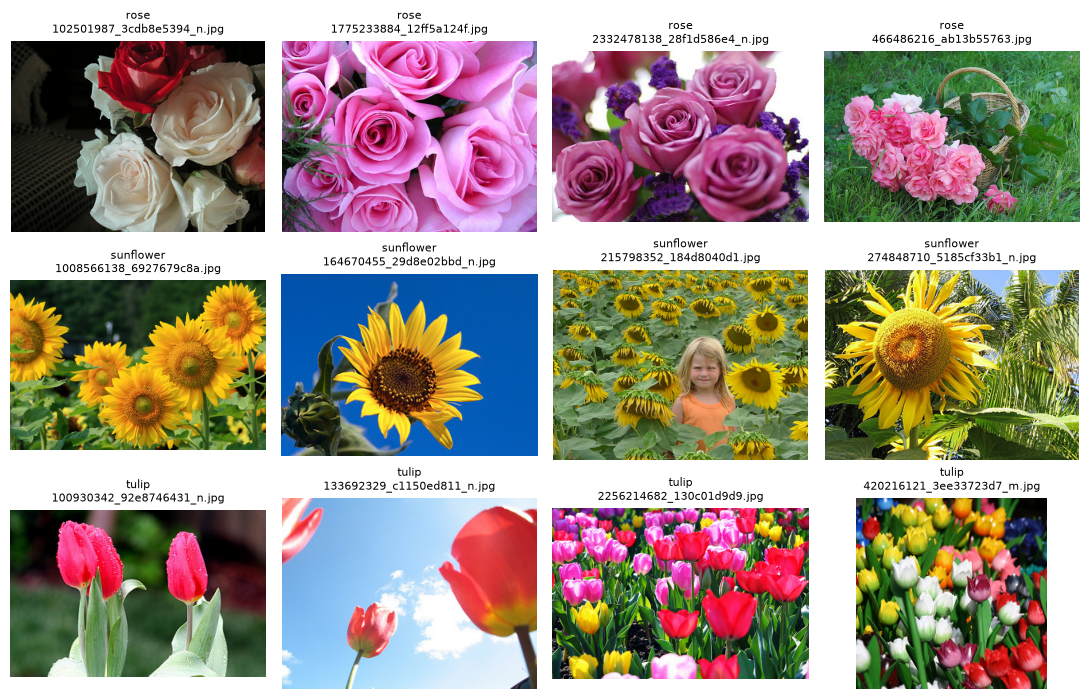

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(11, 7))
for row, c in zip(axes, classes):
    for ax, f in zip(row, files.query("klasse == @c")["datei"].iloc[::25]):
        ax.imshow(Image.open(DATA / "train" / c / f))
        ax.set_title(f"{c}\n{f}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()

**Was wir sehen:** Die Fotos sind sehr verschieden: einzelne Blüten ganz nah, ganze Felder, Sträuße, ein Kind im
Sonnenblumenfeld. Rosen und Tulpen kommen beide in Rot und Rosa vor; bunte Tulpenfelder enthalten auch gelbe Tulpen.
Sonnenblumen sind fast immer gelb mit dunkler Mitte.

### Entscheidung Bildgröße

**Was:** Jedes Netz braucht eine feste Eingabegröße. Der Rechenrahmen erlaubt höchstens 160 × 160. Die Abbildung zeigt
links die Originalgrößen aller Trainingsfotos, rechts ein Foto in verschiedenen Größen und zwei Arten, es quadratisch zu
machen.

**Entscheidung: 160 × 160, gestaucht** (Standard von `image_dataset_from_directory`). 160 ist die größte erlaubte Größe,
und MobileNetV2 gibt es mit Gewichten, die genau auf 160 × 160 vortrainiert wurden. Kleinere Bilder rechnen schneller,
verlieren aber Details wie die Form der Blütenblätter.

**Alternativen verworfen:** 96 oder 128 Pixel (schneller, aber weniger Detail; die Laufzeit ist bei 160 schon klein genug);
`crop_to_aspect_ratio=True` schneidet den Rand ab statt zu stauchen; dabei kann eine Blume am Bildrand verloren gehen. Das
Stauchen verzerrt die Fotos (die meisten sind 4:3) leicht, aber gleich für alle, und Blumen bleiben erkennbar.

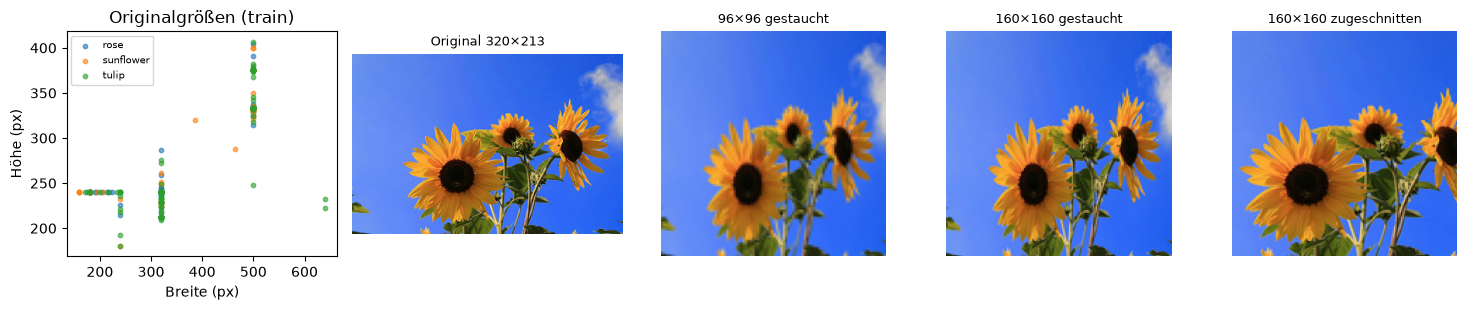

In [7]:
IMG_SIZE = (160, 160)
example = DATA / "train" / "sunflower" / files.query("klasse == 'sunflower'")["datei"].iloc[3]
img = Image.open(example)
w, h = img.size
s = min(w, h)
variants = {f"Original {w}×{h}": img,
            "96×96 gestaucht": img.resize((96, 96)),
            "160×160 gestaucht": img.resize(IMG_SIZE),
            "160×160 zugeschnitten": img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize(IMG_SIZE)}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for c in classes:
    sub = files.query("klasse == @c")
    axes[0].scatter(sub["breite"], sub["hoehe"], s=10, alpha=0.6, label=c)
axes[0].set(xlabel="Breite (px)", ylabel="Höhe (px)", title="Originalgrößen (train)")
axes[0].legend(fontsize=7)
for ax, (title, im) in zip(axes[1:], variants.items()):
    ax.imshow(im)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Was wir sehen:** Die meisten Fotos sind 320 × 240 oder 500 Pixel breit (zwei Streifen in der Grafik), also quer und im
Format 4:3 oder 3:2. Gestaucht auf 160 × 160 bleiben die Sonnenblumen klar erkennbar, nur etwas schmaler; zugeschnitten
fehlt rechts und links ein Stück. Bei 96 × 96 werden die Blütenblätter unscharf. Das stützt 160 × 160 gestaucht.

## Schritt 3: Training und Validierung trennen

**Was:** Wir laden `data/train` mit `image_dataset_from_directory`, wie im Kurs verlangt: `validation_split=0.2`,
`subset="both"`, fester `seed`, `image_size=(160, 160)`. Das ergibt 240 Trainings- und 60 Validierungsfotos. Die
Testfotos laden wir erst in Schritt 8.

**Entscheidung Split: 80/20 mit Seed 42.** 60 Validierungsfotos sind wenig, aber jedes Foto mehr in der Validierung fehlt
dem Training, das ohnehin nur 100 Fotos je Klasse hat. **Alternativen verworfen:** 70/30 (zuverlässigere Validierung, aber
30 Trainingsfotos weniger); eine geschichtete Aufteilung mit scikit-learn oder eine Kreuzvalidierung aller Keras-Modelle
(genauer, aber gegen die Vorgabe des Kurses und fünfmal so viel Rechenzeit). `image_dataset_from_directory` schichtet
nicht; wir prüfen deshalb unten, ob alle Klassen in beiden Teilen ähnlich oft vorkommen. Für die logistische Regression
nutzen wir zusätzlich eine Kreuzvalidierung auf den 240 Trainingsfotos, weil sie dort fast nichts kostet.

In [8]:
BATCH = 32
train_ds, val_ds = keras.utils.image_dataset_from_directory(
    DATA / "train", validation_split=0.2, subset="both", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH)
class_names = train_ds.class_names
class_names

Found 300 files belonging to 3 classes.


Using 240 files for training.


Using 60 files for validation.


E0000 00:00:1793202720.348358  437938 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


['rose', 'sunflower', 'tulip']

**Was wir sehen:** Keras findet 300 Fotos in 3 Klassen und teilt sie in **240** für das Training und **60** für die
Validierung. Die Klassennamen kommen aus den Ordnernamen in alphabetischer Reihenfolge: 0 = rose, 1 = sunflower, 2 = tulip.

**Bilder und Labels aus derselben Schleife.** Für Vorhersagen und Merkmale brauchen wir die Fotos als Arrays. Wir holen
Bild und Label **in derselben Schleife** über den Datensatz. Der Trainingsdatensatz wird bei jedem Durchlauf neu gemischt;
würden wir die Labels in einer zweiten Schleife holen, passten sie nicht mehr zu den Bildern. Der Validierungsdatensatz
wird bei `subset="both"` nicht gemischt (so steht es im Keras-Quelltext); seine Reihenfolge entspricht deshalb
`val_ds.file_paths`, was wir unten für die Fotografen nutzen.

In [9]:
def collect(ds):
    """Return images and labels taken from one and the same loop over the dataset."""
    xs, ys = [], []
    for x, y in ds:
        xs.append(x.numpy())
        ys.append(y.numpy())
    return np.concatenate(xs), np.concatenate(ys)


X_train, y_train = collect(train_ds)
X_val, y_val = collect(val_ds)
print("Training:", X_train.shape, "Validierung:", X_val.shape, "Wertebereich:", X_train.min(), "bis", X_train.max())

Training: (240, 160, 160, 3) Validierung: (60, 160, 160, 3) Wertebereich: 0.0 bis 255.0


**Was wir sehen:** 240 Trainings- und 60 Validierungsfotos als Arrays der Form 160 × 160 × 3; die Pixel liegen zwischen 0 und
255, noch unskaliert. Die Skalierung macht jedes Modell selbst (eingebaute `Rescaling`-Schicht).

**Sind die Klassen in beiden Teilen ähnlich verteilt?** Erst jetzt, nach dem Split, zählen wir die Labels, und zwar
getrennt für Training und Validierung.

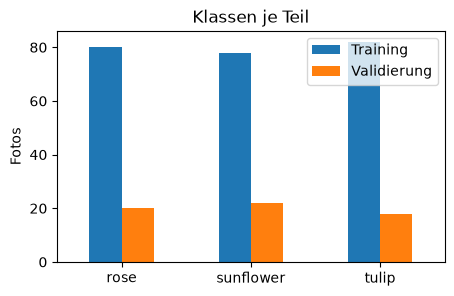

,rose,sunflower,tulip
Training,80,78,82
Validierung,20,22,18


In [10]:
split_counts = pd.DataFrame({"Training": np.bincount(y_train), "Validierung": np.bincount(y_val)}, index=class_names)
ax = split_counts.plot.bar(rot=0, figsize=(5, 3), title="Klassen je Teil")
ax.set_ylabel("Fotos")
plt.show()
split_counts.T

**Was wir sehen:** Im Training 80 Rosen, 78 Sonnenblumen, 82 Tulpen; in der Validierung 20, 22 und 18. Alle drei Klassen
sind in beiden Teilen vertreten, die Abweichung von einer exakten Schichtung beträgt höchstens zwei Fotos. Ein geschichteter
Split ist deshalb nicht nötig.

**Ist ein Foto eine unabhängige Einheit?** `data/LICENSE.txt` nennt für jedes Foto den Fotografen. Hat ein Fotograf
mehrere Fotos derselben Blume gemacht (gleicher Garten, gleiche Kamera, gleiches Licht), dann sind Trainings- und
Validierungsfoto vom selben Fotografen einander ähnlicher als zwei fremde Fotos, und die Validierung wird zu optimistisch.
Wir lesen dazu nur die Zeilen der Fotos aus `data/train`.

**Entscheidung:** Wir bleiben beim Split des Kurses, messen aber, wie viele Validierungsfotos einen Fotografen haben, der
auch im Training vorkommt. **Alternative verworfen:** ein nach Fotografen gruppierter Split; er ist mit
`image_dataset_from_directory` nicht möglich und würde von der Vorgabe des Kurses abweichen.

In [11]:
lic = {}
for line in (DATA / "LICENSE.txt").read_text(encoding="utf-8").splitlines():
    if " CC-BY by " in line:
        path, rest = line.split(" CC-BY by ", 1)
        lic[path.split("/")[-1]] = rest.rsplit(" - ", 1)[0]
train_names = set(files["datei"])
photographer = {n: lic.get(n, "unbekannt") for n in train_names}
tr_phot = {photographer[Path(p).name] for p in train_ds.file_paths}
val_shared = np.array([photographer[Path(p).name] in tr_phot for p in val_ds.file_paths])
print("Fotografen in data/train:", len(set(photographer.values())),
      "| ohne Eintrag:", sum(v == "unbekannt" for v in photographer.values()))
print("Fotos je Fotograf (häufigste):", Counter(photographer.values()).most_common(5))
print(f"Validierungsfotos mit Fotograf auch im Training: {val_shared.sum()} von {len(val_shared)}")

Fotografen in data/train: 156 | ohne Eintrag: 0
Fotos je Fotograf (häufigste): [('liz west', 32), ('Sharon Mollerus', 14), ('Audrey', 10), ('Lori Branham', 9), ('Phyllis Buchanan', 9)]
Validierungsfotos mit Fotograf auch im Training: 39 von 60


**Was wir sehen:** Die 300 Fotos stammen von **156** Fotografen, einer allein (liz west) hat 32 Fotos beigetragen. **39
von 60** Validierungsfotos haben einen Fotografen, der auch im Training vorkommt. Ein Foto ist also nicht ganz unabhängig
vom anderen: Ähnliche Aufnahmen desselben Fotografen machen die Validierung eher zu leicht. Das merken wir uns für die
Einordnung; wie groß der Effekt ist, können wir mit 60 Fotos nicht sauber messen.

## Schritt 4: Den Trainingsteil erkunden

**Was:** Wir zeigen ein Raster von Trainingsfotos mit Label, so wie das Modell sie sieht (160 × 160) und fragen: Was
unterscheidet die Blumen? Ab hier schauen wir nur auf die 240 Trainingsfotos.

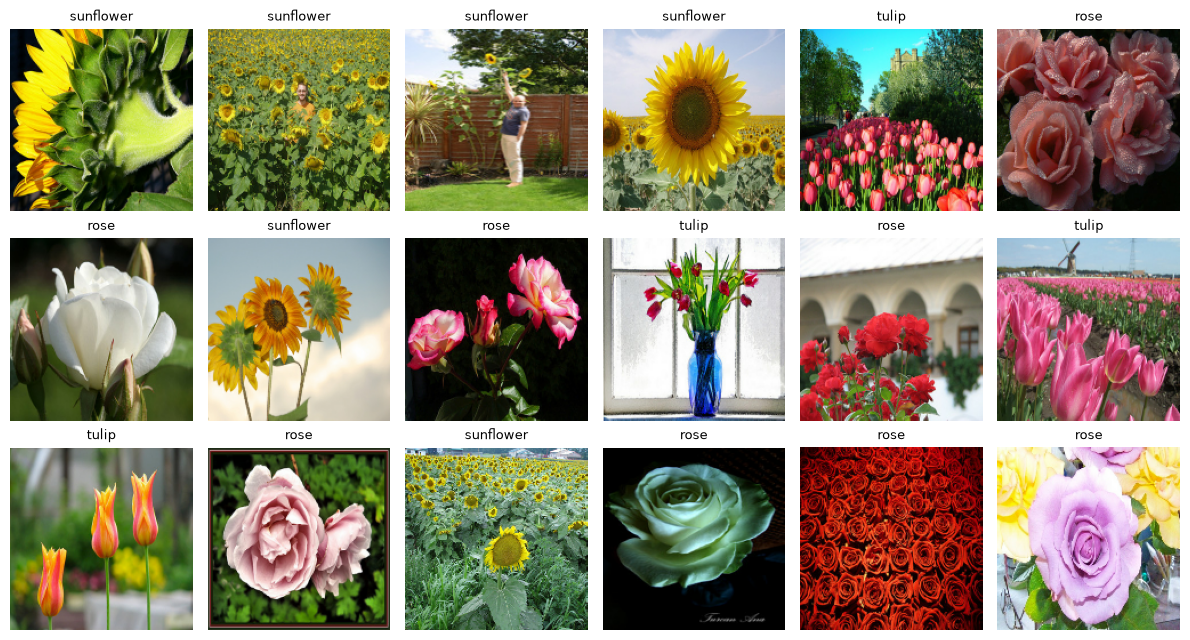

In [12]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6.5))
for ax, i in zip(axes.flat, range(18)):
    ax.imshow(X_train[i].astype("uint8"))
    ax.set_title(class_names[y_train[i]], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Was wir sehen:** So sieht das Modell die Fotos: 160 × 160, leicht gestaucht. Sonnenblumen erkennt man an Gelb und der
dunklen, runden Mitte. Rosen und Tulpen teilen die Farben (Rot, Rosa, Weiß); sie unterscheiden sich vor allem in der
**Form**: Rosen haben viele eng gewickelte Blütenblätter, Tulpen eine glatte Kelchform auf langem Stiel. **Erwartung:** Das
Modell verwechselt am ehesten **Rose und Tulpe**, vor allem bei Sträußen, Feldern aus der Ferne und rosa Blüten.

**Farbe als Merkmal.** Eine einfache Zahl je Foto: der mittlere Rot-, Grün- und Blauwert. Die Abbildung zeigt, ob die
Farbe allein die Klassen trennt. **Warum nur Farbe:** Sie ist das Offensichtlichste; Form und Hintergrund lassen sich nicht
so einfach in eine Zahl fassen, dafür ist das Netz da.

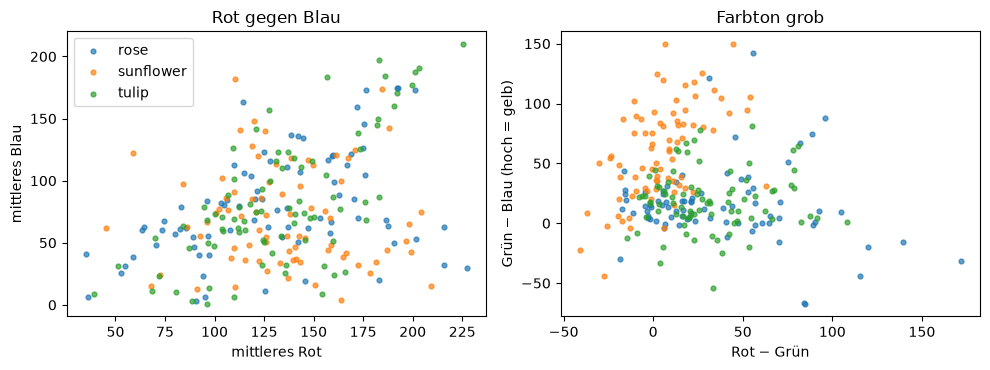

In [13]:
mean_rgb = X_train.mean(axis=(1, 2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for k, c in enumerate(class_names):
    m = y_train == k
    axes[0].scatter(mean_rgb[m, 0], mean_rgb[m, 2], s=12, alpha=0.7, label=c)
    axes[1].scatter(mean_rgb[m, 0] - mean_rgb[m, 1], mean_rgb[m, 1] - mean_rgb[m, 2], s=12, alpha=0.7, label=c)
axes[0].set(xlabel="mittleres Rot", ylabel="mittleres Blau", title="Rot gegen Blau")
axes[1].set(xlabel="Rot − Grün", ylabel="Grün − Blau (hoch = gelb)", title="Farbton grob")
axes[0].legend()
plt.tight_layout()
plt.show()

**Was wir sehen:** Rot gegen Blau trennt die Klassen kaum, alle drei überlappen stark. Im groben Farbton (rechts) liegen
die Sonnenblumen eher oben (mehr Gelb: Grün deutlich über Blau), Rosen und Tulpen liegen übereinander. Farbe hilft also
bei Sonnenblumen, kaum bei Rose gegen Tulpe; das bestätigt die Erwartung aus dem Raster.

**Wie weit kommt man mit Farbe allein?** Eine Ein-Merkmal-Regel als zusätzliche Messlatte: eine logistische Regression nur
auf den drei mittleren Farbwerten, in einer 5-fachen Kreuzvalidierung **nur auf den 240 Trainingsfotos**. Sie zeigt, wie
viel ein Netz über die Farbe hinaus lernen muss. **Warum keine eigene Zeile in der Schlusstabelle:** Der Kurs verlangt genau
zwei Baselines; diese Zahl dient nur der Einordnung.

In [14]:
color_cv = cross_val_score(LogisticRegression(max_iter=5000), mean_rgb / 255, y_train,
                           cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED))
print(f"Nur mittlere Farbe: CV-Genauigkeit {color_cv.mean():.3f} (Folds: {np.round(color_cv, 2)})")

Nur mittlere Farbe: CV-Genauigkeit 0.525 (Folds: [0.54 0.5  0.58 0.5  0.5 ])


**Was wir sehen:** Nur mit den drei mittleren Farbwerten erreicht eine logistische Regression etwa **0,53** Genauigkeit in
der Kreuzvalidierung (Folds 0,50 bis 0,58), besser als Raten (0,33), aber weit weg von brauchbar. Ein gutes Modell muss
Form und Struktur erkennen, nicht nur Farbe.

## Schritt 5: Zwei Baselines

Die Auswahlregel und das Erfolgskriterium stehen seit Schritt 1 fest. Jetzt kommen die ersten Modellergebnisse.

### 5a Zufallsbaseline

**Was:** `DummyClassifier(strategy="most_frequent")` sagt immer die häufigste Klasse des Trainingsteils. Er sieht keine
Pixel, nur die Labels. **Warum:** Jedes Modell, das nicht klar darüber liegt, hat nichts gelernt. **Alternative
verworfen:** `strategy="stratified"` (zufällig nach Häufigkeit raten) schwankt von Lauf zu Lauf und ist im Mittel genauso
gut, also schlechter zu vergleichen.

In [15]:
chance = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
print("Häufigste Klasse im Training:", class_names[chance.predict([[0]])[0]])
print("Validierungsgenauigkeit:", round(accuracy_score(y_val, chance.predict(np.zeros((len(y_val), 1)))), 3))

Häufigste Klasse im Training: tulip
Validierungsgenauigkeit: 0.3


**Was wir sehen:** Die häufigste Klasse im Training ist **Tulpe** (82 Fotos). Wer immer „Tulpe“ sagt, trifft in der
Validierung **0,30** (18 der 60 Fotos sind Tulpen). Das ist die untere Messlatte.

### 5b Kleiner CNN von Grund auf

**Was:** Ein CNN mit drei Blöcken aus Faltung (`Conv2D`) und Pooling (`MaxPooling2D`), wie in dieser Woche gebaut. Die
Pixel (0 bis 255) skaliert eine `Rescaling`-Schicht im Modell auf 0 bis 1; so bekommt jedes Foto genau dieselbe
Vorbereitung, auch später die Testfotos.

**Entscheidung Architektur:** 16, 32, 64 Filter mit 3 × 3-Kernen, danach `Dropout(0.3)` und eine `Dense`-Ausgabe mit drei
Klassen und Softmax. Wir vergleichen zwei Arten, die Merkmalskarten an die Ausgabe zu geben:

- **Flatten:** alle 20 × 20 × 64 Werte der letzten Karte nebeneinander. Viele Parameter in der Ausgabeschicht.
- **GlobalAveragePooling:** je Filter nur der Mittelwert über die Karte, also 64 Werte. Sehr wenige Parameter.

**Verworfen:** ein größerer CNN (mehr Blöcke, mehr Filter). Mit 240 Fotos lernt er vor allem die Trainingsfotos
auswendig; genau diese Grenze soll die Baseline zeigen. Augmentation lassen wir hier weg, damit die Baseline das ist, was
der Kurs verlangt: ein schlichter CNN.

In [16]:
def make_cnn(head):
    layers = [keras.Input((*IMG_SIZE, 3)), keras.layers.Rescaling(1 / 255)]
    for filters in (16, 32, 64):
        layers += [keras.layers.Conv2D(filters, 3, padding="same", activation="relu"), keras.layers.MaxPooling2D()]
    layers.append(keras.layers.Flatten() if head == "flatten" else keras.layers.GlobalAveragePooling2D())
    layers += [keras.layers.Dropout(0.3), keras.layers.Dense(3, activation="softmax")]
    return keras.Sequential(layers, name=f"cnn_{head}")


def n_params(model):
    """Total and trainable number of parameters of a Keras model."""
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    return int(model.count_params()), trainable


cnn_flat = make_cnn("flatten")
cnn_flat.summary()

Model: "cnn_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │        76,803 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,387 (392.14 KB)

 Trainable params: 100,387 (392.14 KB)

 Non-trainable params: 0 (0.00 B)

**Was wir sehen:** Die Zusammenfassung zeigt für jede Schicht die Ausgabeform und die Parameter. Die Faltungen halten
Höhe und Breite (`padding="same"`) und erhöhen die Zahl der Kanäle (3 → 16 → 32 → 64); jedes Pooling halbiert Höhe und
Breite. Gesamt **100 387** Parameter, alle trainierbar.

**Von Hand nachgerechnet.** Eine Faltungsschicht hat je Filter ein Gewicht für jedes Pixel des Kerns und jeden
Eingangskanal, plus einen Bias:

- Erste `Conv2D`: Kern 3 × 3, 3 Eingangskanäle (RGB), 16 Filter: 3 · 3 · 3 · 16 + 16 = 432 + 16 = **448**.
- Zweite `Conv2D`: 3 · 3 · **16** · 32 + 32 = **4 640** (die Eingangskanäle sind jetzt die 16 Filter davor).
- `MaxPooling2D` hat **0** Parameter: Es nimmt nur das Maximum aus 2 × 2 Pixeln und halbiert Höhe und Breite
  (160 → 80 → 40 → 20). Es lernt nichts, macht die Karten aber kleiner.
- `Flatten` hat 0 Parameter, legt aber 20 · 20 · 64 = 25 600 Werte nebeneinander. Die `Dense`-Ausgabe braucht deshalb
  25 600 · 3 + 3 = **76 803** Gewichte, mehr als alle Faltungen zusammen.

Die Faltung teilt ihre Gewichte über das ganze Bild: Derselbe 3 × 3-Kern wird an jeder Stelle angewandt. Deshalb hat sie
trotz 160 × 160 Pixeln nur 448 Parameter; eine `Dense`-Schicht direkt auf den Pixeln bräuchte 160 · 160 · 3 = 76 800
Gewichte **je Neuron**. Wir prüfen die Rechnung mit Keras:

In [17]:
conv1 = cnn_flat.layers[1]
by_hand = 3 * 3 * 3 * 16 + 16
print("Conv2D 1 von Hand:", by_hand, "| Keras:", conv1.count_params())
print("Dense nach Flatten von Hand:", 20 * 20 * 64 * 3 + 3, "| Keras:", cnn_flat.layers[-1].count_params())
cnn_gap = make_cnn("gap")
print("Variante GlobalAveragePooling, Dense-Ausgabe:", cnn_gap.layers[-1].count_params(), "Parameter (64 · 3 + 3)")
pd.DataFrame([n_params(cnn_flat), n_params(cnn_gap)], index=["CNN Flatten", "CNN GAP"],
             columns=["gesamt", "trainierbar"])

Conv2D 1 von Hand: 448 | Keras: 448
Dense nach Flatten von Hand: 76803 | Keras: 76803
Variante GlobalAveragePooling, Dense-Ausgabe: 195 Parameter (64 · 3 + 3)


,gesamt,trainierbar
CNN Flatten,100387,100387
CNN GAP,23779,23779


**Was wir sehen:** Die Rechnung von Hand stimmt mit Keras überein: **448** Parameter für die erste Faltung, **76 803** für
die `Dense`-Ausgabe nach `Flatten`. Mit `GlobalAveragePooling2D` braucht die Ausgabe nur **195** Parameter; der ganze CNN
schrumpft von **100 387** auf **23 779** Parameter. Ein Pooling über die ganze Karte spart also drei Viertel des Modells.

**Training der beiden CNN.** **Was:** Adam mit Lernrate 0,001 (Standard), höchstens 40 Epochen. **Entscheidung:**
`EarlyStopping` auf dem Validierungs-Loss mit Geduld 8 und `restore_best_weights=True`: Das Training stoppt, wenn der
Loss 8 Epochen nicht besser wird, und behält die beste Epoche. **Warum Loss statt Genauigkeit:** Die Genauigkeit springt
bei 60 Fotos in Schritten von 1,7 Punkten, der Loss ändert sich stetig. **Alternative verworfen:** feste Epochenzahl; zu
viele Epochen lernen die Trainingsfotos auswendig, zu wenige verschenken Leistung. Der Preis: Die Validierung bestimmt die
Epochenzahl mit und ist dadurch ein wenig optimistisch.

cnn_flatten: 11 Epochen, beste Epoche 3, val_accuracy 0.667, val_loss 0.759, 15 s


cnn_gap: 38 Epochen, beste Epoche 30, val_accuracy 0.833, val_loss 0.566, 46 s


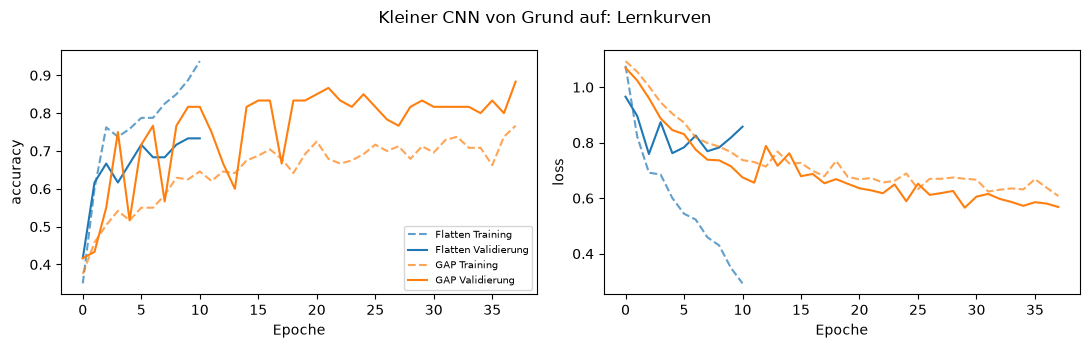

In [18]:
def fit(model, epochs, patience, lr=1e-3, data=None):
    keras.utils.set_random_seed(SEED)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    train, val = data if data is not None else (train_ds, val_ds)
    t = time.time()
    hist = model.fit(train, validation_data=val, epochs=epochs, callbacks=[stop], verbose=0)
    h = pd.DataFrame(hist.history)
    best = h["val_loss"].idxmin()
    print(f"{model.name}: {len(h)} Epochen, beste Epoche {best + 1}, val_accuracy {h.loc[best, 'val_accuracy']:.3f}, "
          f"val_loss {h.loc[best, 'val_loss']:.3f}, {time.time() - t:.0f} s")
    return h


def plot_curves(histories, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        for metric, ax in zip(("accuracy", "loss"), axes):
            ax.plot(h[metric], color=color, ls="--", alpha=0.7, label=f"{name} Training")
            ax.plot(h[f"val_{metric}"], color=color, label=f"{name} Validierung")
            ax.set(xlabel="Epoche", ylabel=metric)
    axes[0].legend(fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


hist_flat = fit(cnn_flat, epochs=40, patience=8)
hist_gap = fit(cnn_gap, epochs=40, patience=8)
plot_curves({"Flatten": hist_flat, "GAP": hist_gap}, "Kleiner CNN von Grund auf: Lernkurven")

**Was wir sehen:** Die **Flatten**-Variante lernt die Trainingsfotos schnell auswendig: Die Trainingsgenauigkeit steigt
auf über 0,9, der Trainings-Loss fällt, der Validierungs-Loss steigt ab Epoche 3 wieder. Das ist **Überanpassung**;
`EarlyStopping` stoppt nach 11 Epochen und behält Epoche 3 (Validierung **0,667**). Die **GAP**-Variante lernt langsamer,
aber stetig, ohne Überanpassung; sie erreicht in Epoche 30 **0,833** Validierungsgenauigkeit. Ihre Trainingsgenauigkeit
liegt unter der Validierung, weil im Training das Dropout mitläuft. Aus 240 Fotos lernt ein CNN von Grund auf also etwas,
aber eine von sechs Validierungsfotos bleibt falsch.

**Welche CNN-Variante wird die Baseline?** Wir wenden die Auswahlregel aus Schritt 1 an.

In [19]:
def val_acc(model):
    return accuracy_score(y_val, model.predict(X_val, verbose=0).argmax(1))


def choose(candidates, tol=1 / len(y_val)):
    """Selection rule of step 1: best validation accuracy, then the simplest within one validation photo."""
    df = pd.DataFrame(candidates).set_index("modell")
    df["in_toleranz"] = df["val"] >= df["val"].max() - tol - 1e-9
    winner = df[df["in_toleranz"]].sort_values(["trainierbar", "stufe"]).index[0]
    return winner, df


cnn_cands = [{"modell": "CNN Flatten", "val": val_acc(cnn_flat), "trainierbar": n_params(cnn_flat)[1], "stufe": 0},
             {"modell": "CNN GAP", "val": val_acc(cnn_gap), "trainierbar": n_params(cnn_gap)[1], "stufe": 0}]
cnn_choice, cnn_table = choose(cnn_cands)
cnn = {"CNN Flatten": cnn_flat, "CNN GAP": cnn_gap}[cnn_choice]
print("Baseline-CNN:", cnn_choice)
cnn_table

Baseline-CNN: CNN GAP


,val,trainierbar,stufe,in_toleranz
modell,,,,
CNN Flatten,0.666667,100387,0,False
CNN GAP,0.833333,23779,0,True


**Was wir sehen:** Die GAP-Variante liegt mit 0,833 klar vor Flatten (0,667) und hat zudem weniger Parameter. Die
**Baseline „CNN von Grund auf“ ist die GAP-Variante.**

## Schritt 6: Vortrainiertes Netz als Merkmalsextraktor

### Entscheidung Basis

**Was:** Ein vortrainiertes Netz aus `keras.applications` ohne seine Ausgabeschicht (`include_top=False`) mit
`pooling="avg"` macht aus jedem Foto einen Merkmalsvektor. Diese Basis wird eingefroren: Sie lernt nichts mehr, sie
übersetzt nur. Wir vergleichen zwei kleine Basen, beide auf ImageNet (1,2 Millionen Fotos, 1 000 Klassen) vortrainiert:

- **MobileNetV2** (Vorschlag des Kurses): 2,3 Millionen Parameter, 1 280 Merkmale, Gewichte für 160 × 160 vorhanden.
- **EfficientNetB0**: 4,0 Millionen Parameter, 1 280 Merkmale, auf ImageNet etwas genauer als MobileNetV2.

**Jede Basis braucht ihr eigenes `preprocess_input`.** MobileNetV2 erwartet Werte von −1 bis 1. Das ist genau
`x / 127.5 − 1`; wir bauen es als `Rescaling`-Schicht **in das Modell** ein, damit jedes Foto (Training, Validierung,
Test) dieselbe Vorbereitung bekommt und niemand sie vergessen kann. EfficientNetB0 skaliert selbst, sein
`preprocess_input` tut nichts. Die Zelle prüft, dass die `Rescaling`-Schicht dasselbe liefert wie `preprocess_input`.

**Wie vergleichen?** Mit der günstigsten Methode: Merkmale einmal berechnen, logistische Regression darauf, und zwar in
einer **5-fachen Kreuzvalidierung nur auf den 240 Trainingsfotos** (`StratifiedKFold` teilt so, dass jede Klasse in jedem
Teil gleich oft vorkommt). So bleibt die Validierung für die späteren Modelle unberührt. **Regel:** EfficientNetB0 ersetzt
MobileNetV2 nur, wenn das 95-%-t-Intervall der gepaarten Differenz der fünf Fold-Genauigkeiten ganz über 0 liegt; sonst
bleibt die kleinere, schnellere Basis des Kurses. **Verworfen:** größere Basen wie ResNet50 (25 Millionen Parameter,
94 MB Download, auf der CPU deutlich langsamer beim Fine-Tuning).

In [20]:
def make_base(name):
    """Frozen pretrained base plus the matching preprocessing layer."""
    if name == "MobileNetV2":
        base = mobilenet_v2.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, pooling="avg", weights="imagenet")
        prep = keras.layers.Rescaling(1 / 127.5, offset=-1)  # same as mobilenet_v2.preprocess_input
    else:
        base = efficientnet.EfficientNetB0(input_shape=(*IMG_SIZE, 3), include_top=False, pooling="avg",
                                           weights="imagenet")
        prep = keras.layers.Identity()  # EfficientNet rescales inside; its preprocess_input is a no-op
    base.trainable = False
    return base, prep


def make_extractor(name):
    base, prep = make_base(name)
    inp = keras.Input((*IMG_SIZE, 3))
    return keras.Model(inp, base(prep(inp), training=False), name=f"extractor_{name}")


x = X_train[:4]
print("Rescaling == preprocess_input:",
      np.allclose(keras.layers.Rescaling(1 / 127.5, offset=-1)(x), mobilenet_v2.preprocess_input(x.copy()), atol=1e-6))

Rescaling == preprocess_input: True


**Was wir sehen:** `True`: Die `Rescaling`-Schicht liefert bis auf Rundung dieselben Werte wie
`mobilenet_v2.preprocess_input`. Wir dürfen sie also statt der Funktion ins Modell einbauen.

**Was die nächste Zelle tut:** Für jede der beiden Basen alle 240 Trainingsfotos einmal durch die eingefrorene Basis
schicken, die Zeit messen und eine logistische Regression (Standard `C = 1`) in fünf festen Folds bewerten. Beide Basen
sehen dieselben Folds; so können wir die Fold-Genauigkeiten paarweise vergleichen.

In [21]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
feats, base_rows = {}, []
for name in ["MobileNetV2", "EfficientNetB0"]:
    ext = make_extractor(name)
    t = time.time()
    feats[name] = ext.predict(X_train, verbose=0)
    secs = time.time() - t
    scores = cross_val_score(LogisticRegression(max_iter=5000), feats[name], y_train, cv=skf)
    base_rows.append({"Basis": name, "Parameter": ext.count_params(), "Sekunden für 240 Fotos": round(secs, 1),
                      "CV-Genauigkeit": scores.mean(), "Fold-Std": scores.std(ddof=1), "folds": scores})
    del ext
bases = pd.DataFrame(base_rows).set_index("Basis")
diff = bases.loc["EfficientNetB0", "folds"] - bases.loc["MobileNetV2", "folds"]
half = stats.t.ppf(0.975, len(diff) - 1) * diff.std(ddof=1) / np.sqrt(len(diff))
print(f"Differenz EfficientNetB0 − MobileNetV2: {diff.mean():+.3f}, 95-%-Intervall [{diff.mean() - half:+.3f}, "
      f"{diff.mean() + half:+.3f}]")
bases.drop(columns="folds").round(3)

Differenz EfficientNetB0 − MobileNetV2: -0.058, 95-%-Intervall [-0.114, -0.002]


,Parameter,Sekunden für 240 Fotos,CV-Genauigkeit,Fold-Std
Basis,,,,
MobileNetV2,2257984,4.4,0.925,0.024
EfficientNetB0,4049571,8.0,0.867,0.056


**Was wir sehen:** Die Tabelle zeigt Parameter, Rechenzeit und CV-Genauigkeit beider Basen, darüber die gepaarte Differenz
mit Intervall. Die Worte zu den Zahlen stehen unter der Grafik.

**Was die nächste Zelle tut:** Sie zeigt die CV-Genauigkeiten als Balken mit der Streuung über die Folds und wendet die
Regel an (EfficientNetB0 nur, wenn das Intervall der Differenz ganz über 0 liegt).

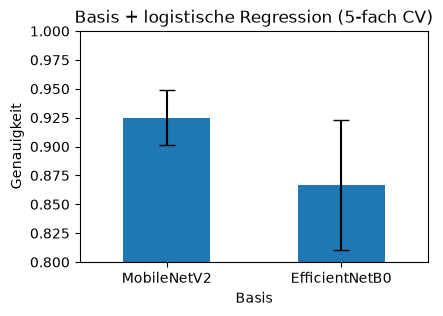

Gewählte Basis: MobileNetV2


In [22]:
ax = bases["CV-Genauigkeit"].plot.bar(yerr=bases["Fold-Std"], rot=0, figsize=(4.5, 3), capsize=6,
                                      title="Basis + logistische Regression (5-fach CV)")
ax.set(ylim=(0.8, 1.0), ylabel="Genauigkeit")
plt.show()
BASE_NAME = "EfficientNetB0" if diff.mean() - half > 0 else "MobileNetV2"
print("Gewählte Basis:", BASE_NAME)

**Was wir sehen:** Die `Rescaling`-Schicht liefert genau dasselbe wie `mobilenet_v2.preprocess_input`. Mit logistischer
Regression auf den Merkmalen erreicht **MobileNetV2 0,925** in der Kreuzvalidierung, **EfficientNetB0 nur 0,867**, bei fast
doppelt so vielen Parametern und 60 % mehr Rechenzeit. Die gepaarte Differenz EfficientNetB0 − MobileNetV2 beträgt −0,058,
das 95-%-Intervall [−0,114; −0,002] liegt ganz **unter** 0. Nach unserer Regel bleibt **MobileNetV2**. Warum das größere
Netz hier schlechter ist, wissen wir nicht sicher; eine Vermutung ist, dass seine Merkmale bei 160 × 160 (es wurde auf
224 × 224 trainiert) weniger gut passen.

### 6a Logistische Regression auf den Merkmalen

**Was:** Wir schicken jedes Foto einmal durch die eingefrorene Basis und speichern die 1 280 Merkmale. Die Fotos kommen aus
den Arrays, die wir in Schritt 3 in **einer** Schleife zusammen mit den Labels geholt haben, Bild und Label passen also.
Dann lernt eine `LogisticRegression` auf den Trainingsmerkmalen.

**Entscheidung Regularisierung `C`:** Kleines `C` heißt starke Regularisierung (kleine Gewichte, glattere Grenzen). Bei
1 280 Merkmalen und nur 240 Fotos kann das Modell sonst die Trainingsfotos auswendig lernen. Wir wählen `C` in einer
5-fachen Kreuzvalidierung auf den Trainingsmerkmalen nach der **Ein-Standardfehler-Regel**: das kleinste `C`, dessen
CV-Genauigkeit höchstens einen Standardfehler unter der besten liegt. **Verworfen:** `C` nach der Validierung wählen; dann
wäre ihre Genauigkeit für die Modellwahl schon verbraucht.

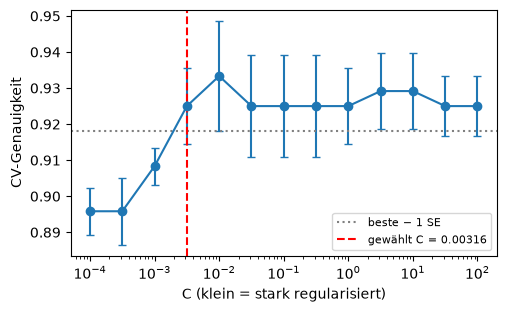

In [23]:
extractor = make_extractor(BASE_NAME)
F_train = feats[BASE_NAME]
F_val = extractor.predict(X_val, verbose=0)
Cs = np.logspace(-4, 2, 13)
cv = np.array([cross_val_score(LogisticRegression(C=C, max_iter=5000), F_train, y_train, cv=skf) for C in Cs])
cv_mean, cv_se = cv.mean(1), cv.std(1, ddof=1) / np.sqrt(cv.shape[1])
best = cv_mean.argmax()
C_best = Cs[np.argmax(cv_mean >= cv_mean[best] - cv_se[best])]
plt.figure(figsize=(5.5, 3.2))
plt.errorbar(Cs, cv_mean, yerr=cv_se, marker="o", capsize=3)
plt.axhline(cv_mean[best] - cv_se[best], color="grey", ls=":", label="beste − 1 SE")
plt.axvline(C_best, color="red", ls="--", label=f"gewählt C = {C_best:.3g}")
plt.xscale("log")
plt.xlabel("C (klein = stark regularisiert)")
plt.ylabel("CV-Genauigkeit")
plt.legend(fontsize=8)
plt.show()

**Was wir sehen:** Die CV-Genauigkeit ist zwischen C = 0,003 und C = 100 fast flach (0,925 bis 0,933); erst bei sehr
starker Regularisierung (C ≤ 0,001) fällt sie ab. Die beste ist C = 0,01 (0,933); die Ein-Standardfehler-Regel wählt das
kleinere **C = 0,0032** (0,925). Das beste C liegt nicht am Rand des Rasters; der Bereich ist also groß genug.

In [24]:
logreg = LogisticRegression(C=C_best, max_iter=5000).fit(F_train, y_train)
logreg_params = int(logreg.coef_.size + logreg.intercept_.size)
print("Parameter der logistischen Regression:", logreg_params, "(1 280 · 3 + 3)")
print("Trainingsgenauigkeit:", round(logreg.score(F_train, y_train), 3),
      "| Validierungsgenauigkeit:", round(logreg.score(F_val, y_val), 3))

Parameter der logistischen Regression: 3843 (1 280 · 3 + 3)
Trainingsgenauigkeit: 0.992 | Validierungsgenauigkeit: 0.933


**Was wir sehen:** Die logistische Regression hat **3 843** Parameter. Sie trifft im Training **0,992** und in der
Validierung **0,933** (56 von 60). Die Lücke ist klein, obwohl 1 280 Merkmale auf 240 Fotos kommen: Die starke
Regularisierung wirkt. Schon dieser einfache Kopf schlägt den CNN von Grund auf (0,833) deutlich.

**Nullprobe.** Wenn die Kette irgendwo die Labels „sieht“, wo sie es nicht dürfte, findet sie auch in zufällig vertauschten
Labels ein Muster. Wir vertauschen die Trainingslabels und wiederholen die Kreuzvalidierung. **Erwartung:** etwa ein
Drittel, also Zufall.

In [25]:
y_perm = np.random.default_rng(SEED).permutation(y_train)
null_scores = cross_val_score(LogisticRegression(C=C_best, max_iter=5000), F_train, y_perm, cv=skf)
print(f"CV-Genauigkeit mit vertauschten Labels: {null_scores.mean():.3f} (Folds: {np.round(null_scores, 2)})")

CV-Genauigkeit mit vertauschten Labels: 0.325 (Folds: [0.31 0.44 0.31 0.29 0.27])


**Was wir sehen:** Mit vertauschten Labels erreicht dieselbe Kette **0,325**, also Zufall (ein Drittel). Die Kette lernt
nur dann etwas, wenn die Labels zu den Bildern passen; ein verstecktes Leck gibt es hier nicht.

**Fast gleiche Fotos zwischen Training und Validierung?** Mit den Merkmalen können wir ähnliche Fotos finden: Zwei
Merkmalsvektoren, die fast in dieselbe Richtung zeigen (Kosinus-Ähnlichkeit nahe 1), gehören zu fast gleichen Fotos. Wir
zeigen die vier ähnlichsten Paare aus Training und Validierung. **Warum:** Ein fast doppeltes Foto in beiden Teilen macht
die Validierung zu leicht. **Entscheidung:** Wir zählen Paare mit Ähnlichkeit über 0,90 als „fast gleich“ (die Schwelle
legen wir anhand der Bilder unten fest) und melden in der Modellwahl zusätzlich die Genauigkeit ohne diese Fotos.
**Verworfen:** die Fotos zu löschen; der Split ist vom Kurs vorgegeben, und gelöschte Fotos fehlen dem Training.

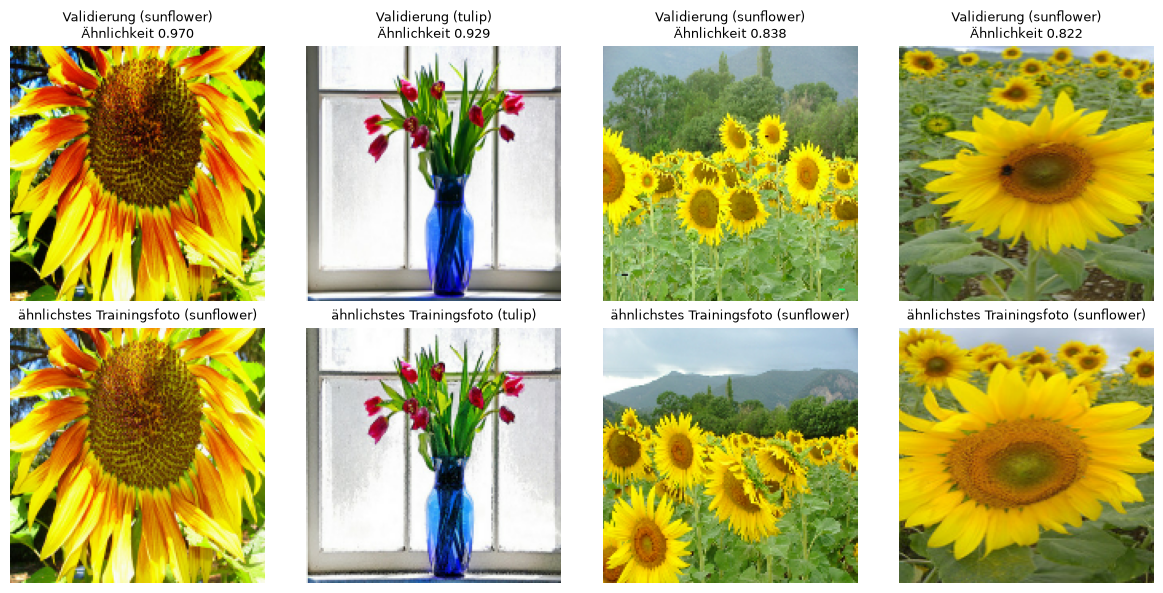

Validierungsfotos mit Ähnlichkeit > 0.9 zu einem Trainingsfoto: 2 von 60


In [26]:
def unit(F):
    return F / np.linalg.norm(F, axis=1, keepdims=True)


sim = unit(F_val) @ unit(F_train).T
top = np.argsort(sim.max(1))[::-1][:4]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, i in enumerate(top):
    k = sim[i].argmax()
    axes[0, j].imshow(X_val[i].astype("uint8"))
    axes[0, j].set_title(f"Validierung ({class_names[y_val[i]]})\nÄhnlichkeit {sim[i, k]:.3f}", fontsize=9)
    axes[1, j].imshow(X_train[k].astype("uint8"))
    axes[1, j].set_title(f"ähnlichstes Trainingsfoto ({class_names[y_train[k]]})", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()
NEAR_DUP = 0.90
near_dup_val = sim.max(1) > NEAR_DUP
print(f"Validierungsfotos mit Ähnlichkeit > {NEAR_DUP} zu einem Trainingsfoto:", int(near_dup_val.sum()), "von", len(sim))

**Was wir sehen:** Zwei Validierungsfotos haben im Training einen fast identischen Zwilling: eine Sonnenblume
(Ähnlichkeit 0,970) und ein Tulpenstrauß am Fenster (0,929), der im Training noch einmal leicht anders zugeschnitten
vorkommt. Ab etwa 0,84 sind es nur noch ähnliche Motive (Sonnenblumenfelder), keine Kopien mehr. Deshalb die Schwelle
0,90. **2 von 60** Validierungsfotos sind also praktisch schon im Training; das macht die Validierung um bis zu zwei Fotos zu
leicht.

### 6b Dense-Kopf in Keras

**Was:** Dasselbe in einem Keras-Modell: Foto → Vorbereitung → eingefrorene Basis → `Dropout(0.2)` → `Dense(3, softmax)`.
Das Modell lernt auf den Fotos selbst, nicht auf gespeicherten Merkmalen; das brauchen wir gleich für Augmentation und
Fine-Tuning.

**Entscheidung Kopf:** nur eine `Dense`-Ausgabeschicht (wie im Kurs), mit leichtem Dropout gegen Auswendiglernen.
**Verworfen:** eine versteckte Schicht im Kopf; ob sie hilft, entscheidet die Suche mit Keras Tuner in Schritt 7c.
`base(x, training=False)` hält die Basis im Inferenzmodus. Lernrate 0,001 (Adam-Standard), höchstens 30 Epochen,
`EarlyStopping` mit Geduld 5.

In [27]:
def make_transfer(augment=None, dropout=0.2, name=None):
    base, prep = make_base(BASE_NAME)
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp) if augment is not None else inp
    x = base(prep(x), training=False)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(3, activation="softmax")(x)
    name = name or ("transfer_aug" if augment is not None else "transfer_dense")
    return keras.Model(inp, out, name=name), base


dense, _ = make_transfer()
print("Parameter gesamt / trainierbar:", n_params(dense))
hist_dense = fit(dense, epochs=30, patience=5)

Parameter gesamt / trainierbar: (2261827, 3843)


transfer_dense: 22 Epochen, beste Epoche 17, val_accuracy 0.917, val_loss 0.210, 70 s


**Was wir sehen:** Das Modell hat **2 261 827** Parameter, davon nur **3 843** trainierbar. Das Training stoppt nach 22
Epochen, die beste Epoche ist 17 mit **0,917** Validierungsgenauigkeit (55 von 60) und Validierungs-Loss 0,210. Das ist ein
Foto weniger als die logistische Regression; bei 60 Fotos ist das kein echter Unterschied.

Fast alle Parameter stecken in der eingefrorenen Basis, trainiert werden nur die 1 280 · 3 + 3 = 3 843 Gewichte der
Ausgabe, genauso viele wie bei der logistischen Regression. **Eingefroren** heißt: Die Gewichte der Basis stehen nicht in
`trainable_weights`, der Optimierer fasst sie nicht an.

## Schritt 7: Das Modell verbessern

### 7a Augmentation

**Was:** Augmentations-Schichten verändern jedes Trainingsfoto in jeder Epoche zufällig ein wenig. So sieht das Netz aus
240 Fotos viele Varianten. Die Schichten wirken **nur im Training**; bei Vorhersagen reichen sie das Foto unverändert
durch, also bleibt die Vorbereitung für Validierung und Test gleich.

**Entscheidung:** `RandomFlip("horizontal")`, `RandomRotation(0.1)` (bis ±36°), `RandomZoom(0.2)`. Eine gespiegelte oder
leicht gedrehte Rose bleibt eine Rose. **Verworfen:** `RandomContrast` oder Farbänderungen, weil die Farbe (Schritt 4) eines
der stärksten Merkmale ist, besonders für Sonnenblumen; vertikales Spiegeln, weil Blumen fast immer mit dem Stiel nach
unten fotografiert sind. Die Abbildung zeigt, was die Schichten aus einem Trainingsfoto machen.

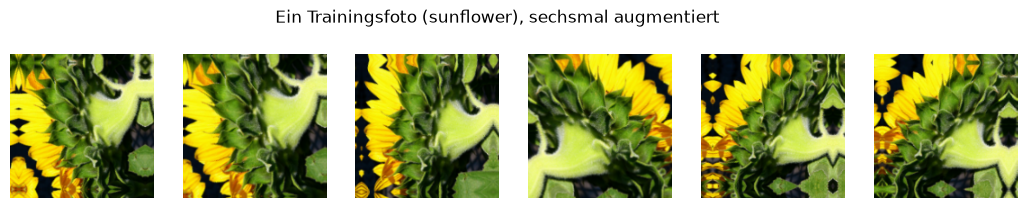

In [28]:
augment = keras.Sequential([keras.layers.RandomFlip("horizontal"), keras.layers.RandomRotation(0.1),
                            keras.layers.RandomZoom(0.2)], name="augmentation")
fig, axes = plt.subplots(1, 6, figsize=(13, 2.4))
for ax in axes:
    ax.imshow(np.clip(augment(X_train[:1], training=True)[0], 0, 255).astype("uint8"))
    ax.axis("off")
fig.suptitle(f"Ein Trainingsfoto ({class_names[y_train[0]]}), sechsmal augmentiert")
plt.show()

**Was wir sehen:** Sechs Varianten desselben Fotos: mal gespiegelt, leicht gedreht, näher herangezoomt. Die Blume bleibt
in jeder Variante gut erkennbar; an den Rändern füllt Keras die gedrehten Ecken mit gespiegelten Pixeln auf. Die
Veränderungen sind also stark genug, um neue Varianten zu erzeugen, aber nicht so stark, dass die Blume verloren geht.

transfer_aug: 30 Epochen, beste Epoche 29, val_accuracy 0.950, val_loss 0.173, 129 s


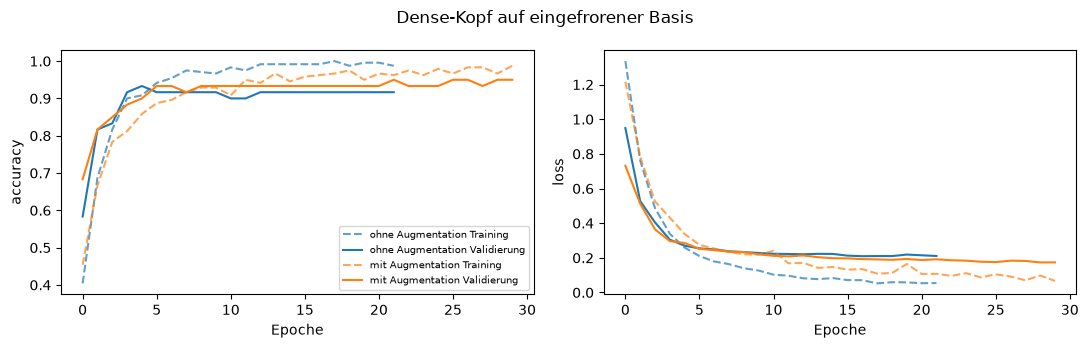

In [29]:
dense_aug, aug_base = make_transfer(augment=augment)
hist_aug = fit(dense_aug, epochs=30, patience=5)
plot_curves({"ohne Augmentation": hist_dense, "mit Augmentation": hist_aug}, "Dense-Kopf auf eingefrorener Basis")

**Was wir sehen:** Ohne Augmentation erreicht die Trainingsgenauigkeit fast 1,0 und der Trainings-Loss fällt weit unter
den Validierungs-Loss: Der Kopf lernt die 240 Fotos auswendig. Mit Augmentation liegen Training und Validierung näher
beieinander; die Validierung erreicht **0,950** (57 von 60) bei Loss **0,173** statt 0,917 und 0,210. Das Training lief alle
30 Epochen (beste Epoche 29), mehr Epochen hätten vielleicht noch etwas gebracht. Der Gewinn beträgt zwei
Validierungsfotos; das ist eine Tendenz, kein gesicherter Fortschritt.

### 7b Fine-Tuning

**Was:** Wir tauen die obersten Schichten der Basis auf und trainieren sie mit einer viel kleineren Lernrate weiter.
Startpunkt ist das Modell mit Augmentation aus 7a: Erst wenn der Kopf vernünftig gelernt hat, dürfen die Schichten der
Basis nachjustiert werden; mit einem zufälligen Kopf würden große Fehlersignale die vortrainierten Gewichte zerstören.

**`BatchNormalization` bleibt eingefroren.** Diese Schichten merken sich Mittelwert und Streuung aus ImageNet. Tauen wir sie
auf, rechnen sie mit den Statistiken unserer kleinen Batches, und die Validierungsgenauigkeit bricht in der ersten Epoche
ein. `base(x, training=False)` allein reicht dafür nicht; wir setzen in einer Schleife über `base.layers` für jede
`BatchNormalization`-Schicht `trainable = False`.

**Entscheidungen: wie viele Schichten, welche Lernrate.** Wir probieren die obersten 10, 30 und 60 der 155 Schichten
(eine Schicht ist hier auch eine Aktivierung oder `BatchNormalization`; die Tabelle zeigt deshalb die tatsächlich
trainierbaren Gewichte) und die Lernraten 1e-5 und 1e-4 (100- bzw. 10-mal kleiner als beim Kopf). Höchstens 15 Epochen,
`EarlyStopping` mit Geduld 4. Gewählt wird nach der Regel aus Schritt 1; bei Gleichstand gewinnt die Variante mit weniger
trainierbaren Gewichten, danach die kleinere Lernrate (sie verändert die Basis weniger). **Verworfen:** die ganze Basis auftauen; 2,2 Millionen Gewichte aus 240 Fotos zu lernen, führt
fast sicher zum Auswendiglernen, und das Training dauert auf der CPU ein Vielfaches.

In [30]:
aug_weights = dense_aug.get_weights()


def make_finetuned(n_top, lr):
    model, base = make_transfer(augment=augment, name=f"finetune_top{n_top}_lr{lr:g}")
    model.set_weights(aug_weights)  # start from the trained augmentation model
    base.trainable = True
    for layer in base.layers[:-n_top]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False  # keep BatchNormalization frozen
    return model, base

**Was die nächste Zelle tut:** Sie trainiert die sechs Varianten (3 Schichtzahlen × 2 Lernraten), jede vom selben
Startpunkt (dem Augmentationsmodell), und zählt dabei, wie viele `BatchNormalization`-Schichten trainierbar sind (es
sollten 0 sein). **Warum derselbe Startpunkt:** Sonst würden wir Startglück statt Schichtzahl und Lernrate vergleichen.
**Verworfen:** die Varianten nacheinander auf demselben Modell weitertrainieren; dann hinge jede Variante von der vorigen ab.

In [31]:
ft_models, ft_hists, ft_rows = {}, {}, []
for n_top in (10, 30, 60):
    for lr in (1e-5, 1e-4):
        model, base = make_finetuned(n_top, lr)
        bn_trainable = sum(l.trainable for l in base.layers if isinstance(l, keras.layers.BatchNormalization))
        ft_hists[(n_top, lr)] = fit(model, epochs=15, patience=4, lr=lr)
        ft_models[(n_top, lr)] = model
        ft_rows.append({"modell": model.name, "n_top": n_top, "lr": lr, "val": val_acc(model),
                        "val_loss": ft_hists[(n_top, lr)]["val_loss"].min(), "trainierbar": n_params(model)[1],
                        "stufe": lr, "BN_trainierbar": bn_trainable})

finetune_top10_lr1e-05: 8 Epochen, beste Epoche 4, val_accuracy 0.950, val_loss 0.167, 33 s


finetune_top10_lr0.0001: 10 Epochen, beste Epoche 6, val_accuracy 0.950, val_loss 0.185, 43 s


finetune_top30_lr1e-05: 13 Epochen, beste Epoche 9, val_accuracy 0.950, val_loss 0.140, 58 s


finetune_top30_lr0.0001: 10 Epochen, beste Epoche 6, val_accuracy 0.950, val_loss 0.123, 47 s


finetune_top60_lr1e-05: 8 Epochen, beste Epoche 4, val_accuracy 0.950, val_loss 0.144, 43 s


finetune_top60_lr0.0001: 13 Epochen, beste Epoche 9, val_accuracy 0.933, val_loss 0.150, 63 s


**Was wir sehen:** Für jede Variante eine Zeile: Epochen bis zum Stopp, beste Epoche, Validierungsgenauigkeit und -Loss,
Laufzeit (zwischen etwa einer halben und einer Minute je Variante). Ausgewertet wird in der nächsten Zelle.

**Was die nächste Zelle tut:** Sie wendet die Auswahlregel an und zeigt Genauigkeit und Loss je Schichtzahl und Lernrate.

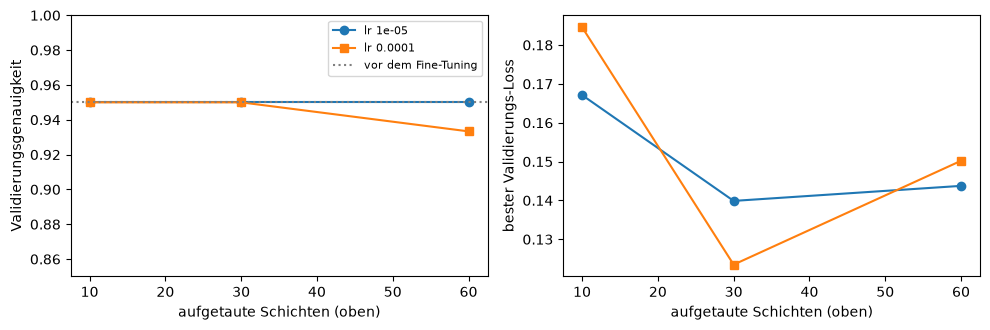

Gewählte Fine-Tuning-Variante: finetune_top10_lr1e-05


,n_top,lr,val,val_loss,trainierbar,BN_trainierbar,in_toleranz
modell,,,,,,,
finetune_top10_lr1e-05,10,1e-05,0.950,0.167,729283,0,True
finetune_top10_lr0.0001,10,0.0001,0.950,0.185,729283,0,True
finetune_top30_lr1e-05,30,1e-05,0.950,0.140,1514563,0,True
finetune_top30_lr0.0001,30,0.0001,0.950,0.123,1514563,0,True
finetune_top60_lr1e-05,60,1e-05,0.950,0.144,1935619,0,True
finetune_top60_lr0.0001,60,0.0001,0.933,0.150,1935619,0,True


In [32]:
ft_choice, ft_table = choose(ft_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for lr, marker in ((1e-5, "o"), (1e-4, "s")):
    sub = ft_table[ft_table["lr"] == lr]
    axes[0].plot(sub["n_top"], sub["val"], marker=marker, label=f"lr {lr:g}")
    axes[1].plot(sub["n_top"], sub["val_loss"], marker=marker, label=f"lr {lr:g}")
axes[0].axhline(val_acc(dense_aug), color="grey", ls=":", label="vor dem Fine-Tuning")
axes[0].set(xlabel="aufgetaute Schichten (oben)", ylabel="Validierungsgenauigkeit", ylim=(0.85, 1.0))
axes[1].set(xlabel="aufgetaute Schichten (oben)", ylabel="bester Validierungs-Loss")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Gewählte Fine-Tuning-Variante:", ft_choice)
ft_table.drop(columns="stufe").assign(lr=ft_table["lr"].map("{:g}".format)).round(3)

**Was wir sehen:** Fünf der sechs Varianten erreichen genau **0,950**, wie das Modell vor dem Fine-Tuning; nur 60 Schichten
mit Lernrate 1e-4 fallen auf 0,933. Der Validierungs-Loss sinkt am meisten bei 30 Schichten (0,123 bzw. 0,140 statt
0,173). Die Genauigkeit unterscheidet die Varianten also nicht; nach unserer Regel gewinnt die einfachste:
**10 Schichten, Lernrate 1e-5** (729 283 trainierbare Gewichte). In allen Varianten sind **0** `BatchNormalization`-Schichten
trainierbar, wie verlangt. Auf Validierungsgenauigkeit bezogen bringt Fine-Tuning hier nichts Messbares.

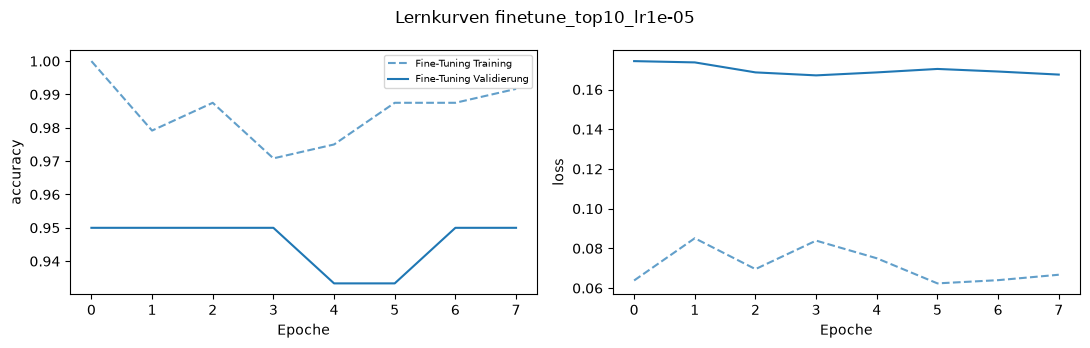

In [33]:
ft_key = tuple(ft_table.loc[ft_choice, ["n_top", "lr"]])
finetuned = ft_models[(int(ft_key[0]), float(ft_key[1]))]
plot_curves({"Fine-Tuning": ft_hists[(int(ft_key[0]), float(ft_key[1]))]}, f"Lernkurven {ft_choice}")

**Was wir sehen:** Die Validierungsgenauigkeit startet bei 0,950 und bleibt dort (kurz 0,933); der Validierungs-Loss sinkt
kaum (0,174 → 0,167). Es gibt keinen Einbruch in der ersten Epoche, die eingefrorenen `BatchNormalization`-Schichten wirken
also. Mit Lernrate 1e-5 verschiebt das Fine-Tuning die Gewichte nur sehr wenig.

### 7c Suche nach den Hyperparametern des Kopfes mit Keras Tuner

**Was:** Keras Tuner probiert Kombinationen von Hyperparametern aus und merkt sich die beste. Wir suchen den Kopf auf der
eingefrorenen Basis:

- versteckte `Dense`-Schicht mit 0 (keine), 64, 128 oder 256 Neuronen,
- Dropout-Rate 0,0 bis 0,5 in Schritten von 0,1,
- Lernrate zwischen 1e-4 und 1e-2 (logarithmisch).

**Entscheidungen:** `RandomSearch` mit 10 Versuchen (Obergrenze des Rechenrahmens), `directory` in `arbeit/tuner`.
Gesucht wird **auf den gespeicherten Merkmalen** aus Schritt 6: Da die Basis eingefroren ist, liefert sie für jedes Foto
immer dieselben Merkmale; jeder Versuch dauert so Sekunden statt Minuten. Das fertige Modell setzen wir danach wieder auf
die Basis, sodass es wie alle anderen Fotos als Eingabe nimmt. Ziel der Suche ist der **Validierungs-Loss**, weil die
Genauigkeit bei 60 Fotos viele Gleichstände hat.

**Verworfen:** `Hyperband` (lohnt sich bei langen Trainings, die es früh abbricht; unsere sind ohnehin kurz); die Suche mit
Augmentation auf den Fotos (jeder Versuch müsste alle Fotos durch die Basis schicken, 10 Versuche kosteten mehrere
Minuten); mehr als 10 Versuche (Rechenrahmen, und je mehr Versuche auf denselben 60 Validierungsfotos, desto optimistischer
ist der beste).

In [34]:
N_FEAT = F_train.shape[1]


def build_head(hp):
    units = hp.Choice("units", [0, 64, 128, 256])
    inp = keras.Input((N_FEAT,))
    x = keras.layers.Dense(units, activation="relu")(inp) if units else inp
    x = keras.layers.Dropout(hp.Float("dropout", 0.0, 0.5, step=0.1))(x)
    out = keras.layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inp, out, name="tuned_head")
    model.compile(optimizer=keras.optimizers.Adam(hp.Float("lr", 1e-4, 1e-2, sampling="log")),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


tuner = kt.RandomSearch(build_head, objective="val_loss", max_trials=10, seed=SEED,
                        directory=WORK / "tuner", project_name="flowers_head", overwrite=True)
keras.utils.set_random_seed(SEED)
t = time.time()
tuner.search(F_train, y_train, validation_data=(F_val, y_val), epochs=100, batch_size=BATCH, verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
print(f"Suche: {time.time() - t:.0f} s")

Suche: 38 s


**Was wir sehen:** Die zehn Versuche dauerten zusammen weniger als eine Minute, weil auf den gespeicherten Merkmalen gesucht
wurde.

**Was die nächste Zelle tut:** Sie holt jeden Versuch an seiner besten Epoche zurück, rechnet seine
Validierungsgenauigkeit nach und zeigt alle Versuche in einer Grafik (Lernrate, Loss, Neuronen, Dropout). **Warum
nachrechnen:** Keras Tuner speichert nur den Loss der besten Epoche, wir wollen auch die Genauigkeit sehen.

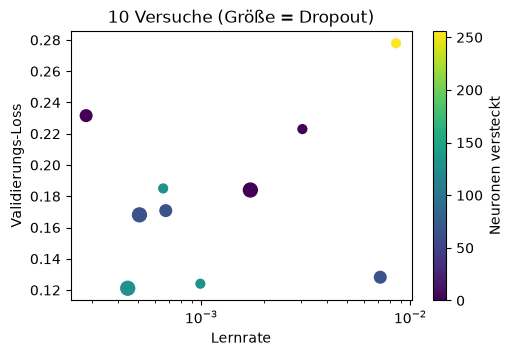

,units,dropout,lr,val_loss,val_accuracy
0,128,0.4,0.0004,0.1211,0.9500
1,128,0.0,0.0010,0.1240,0.9500
2,64,0.2,0.0072,0.1282,0.9500
3,64,0.4,0.0005,0.1681,0.9500
4,64,0.2,0.0007,0.1708,0.9333
5,0,0.4,0.0017,0.1840,0.9167
6,128,0.0,0.0007,0.1850,0.9333
7,0,0.0,0.0030,0.2230,0.9333
8,0,0.2,0.0003,0.2316,0.9333
9,256,0.0,0.0085,0.2779,0.9333


In [35]:
best_trials = tuner.oracle.get_best_trials(num_trials=10)
heads = tuner.get_best_models(num_models=10)  # each restored at its best epoch
trials = pd.DataFrame([{**tr.hyperparameters.values, "val_loss": tr.score,
                        "val_accuracy": accuracy_score(y_val, h.predict(F_val, verbose=0).argmax(1))}
                       for tr, h in zip(best_trials, heads)])
fig, ax = plt.subplots(figsize=(5.5, 3.5))
sc = ax.scatter(trials["lr"], trials["val_loss"], c=trials["units"], s=40 + 150 * trials["dropout"], cmap="viridis")
ax.set(xscale="log", xlabel="Lernrate", ylabel="Validierungs-Loss", title="10 Versuche (Größe = Dropout)")
plt.colorbar(sc, label="Neuronen versteckt")
plt.show()
trials.round(4)

**Was wir sehen:** Die Suche dauerte unter einer Minute. Die besten drei Versuche haben eine versteckte Schicht (128 oder
64 Neuronen) und Validierungs-Loss um 0,12; Köpfe ohne versteckte Schicht liegen bei 0,18 bis 0,23. Bei der
**Genauigkeit** liegen dagegen alle zehn Versuche zwischen 0,917 und 0,950, also innerhalb von zwei Fotos. Die versteckte
Schicht macht die Wahrscheinlichkeiten etwas besser, die Entscheidungen kaum.

In [36]:
best_hp = tuner.get_best_hyperparameters(1)[0]
best_head = tuner.get_best_models(1)[0]
tuned_base, tuned_prep = make_base(BASE_NAME)
inp = keras.Input((*IMG_SIZE, 3))
tuned = keras.Model(inp, best_head(tuned_base(tuned_prep(inp), training=False)), name="transfer_tuned")
print("Beste Hyperparameter:", best_hp.values)
print("Parameter gesamt / trainierbar:", n_params(tuned))
print("Validierungsgenauigkeit (Fotos als Eingabe):", round(val_acc(tuned), 3))

Beste Hyperparameter: {'units': 128, 'dropout': 0.4, 'lr': 0.00044412650444693207}
Parameter gesamt / trainierbar: (2422339, 164355)


Validierungsgenauigkeit (Fotos als Eingabe): 0.95


**Was wir sehen:** Der beste Kopf hat **128** versteckte Neuronen, Dropout **0,4** und Lernrate **0,00044**. Auf die Basis
gesetzt hat das Modell 2 422 339 Parameter, davon **164 355** trainierbar (1 280 · 128 + 128 + 128 · 3 + 3). Mit Fotos als
Eingabe erreicht es **0,950** Validierungsgenauigkeit, genau wie auf den Merkmalen: Der Umweg über die gespeicherten
Merkmale verändert nichts.

### Modellwahl auf der Validierung

**Was:** Alle Modelle mit ihrer Validierungsgenauigkeit, nach der Regel aus Schritt 1. Wir speichern jedes Modell in einer
eigenen Variable (`chance`, `cnn`, `logreg` mit `extractor`, `dense`, `dense_aug`, `finetuned`, `tuned`), damit wir in
Schritt 8 alle auswerten können. Die Abbildung zeigt die Genauigkeiten mit dem Toleranzband (ein Foto unter dem besten).

Die „Stufe“ ordnet Gleichstände bei gleich vielen trainierbaren Parametern: logistische Regression (0) vor Dense-Kopf (1)
vor Augmentation (2) vor Tuner (3) vor Fine-Tuning (4).

In [37]:
def predict_proba(name, X):
    """Class probabilities of every model, each with its own built-in preprocessing."""
    if name == "Zufall (häufigste Klasse)":
        return chance.predict_proba(np.zeros((len(X), 1)))
    if name == "Basis + logistische Regression":
        return logreg.predict_proba(extractor.predict(X, verbose=0))
    return models[name].predict(X, verbose=0)


models = {f"CNN von Grund auf ({cnn_choice[4:]})": cnn, "Basis + Dense-Kopf": dense, "Dense-Kopf + Augmentation": dense_aug,
          f"Fine-Tuning ({ft_choice})": finetuned, "Keras Tuner (Kopf)": tuned}
stage = dict(zip(models, [5, 1, 2, 4, 3]))  # tie order; the CNN never ties (different parameter count)
param_info = {"Zufall (häufigste Klasse)": (None, None, None),
              "Basis + logistische Regression": (extractor.count_params() + logreg_params, logreg_params, 0)}
param_info.update({n: (*n_params(m), stage[n]) for n, m in models.items()})
names = list(param_info)

**Was die nächste Zelle tut:** Sie berechnet für jedes Modell die Wahrscheinlichkeiten auf den Validierungsfotos, wendet die
Auswahlregel aus Schritt 1 an und zeigt als Sensitivitätsprüfung zweierlei: welches Modell stur nach dem Maximum gewonnen
hätte und wie die Genauigkeit ohne die zwei fast gleichen Validierungsfotos aussieht.

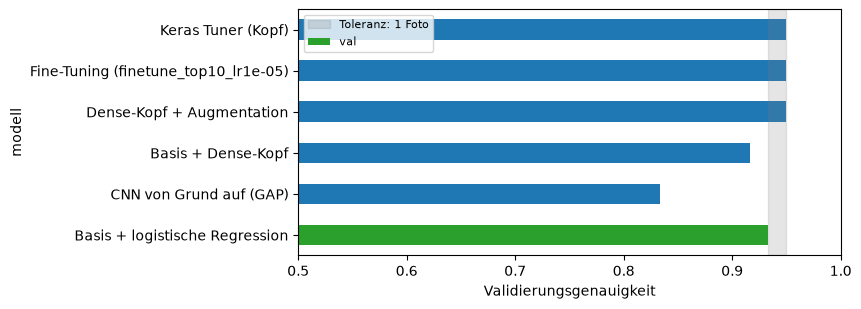

Gewähltes Modell: Basis + logistische Regression | nur nach dem Maximum gewählt: Dense-Kopf + Augmentation


,val,trainierbar,stufe,val ohne fast gleiche,in_toleranz
modell,,,,,
Basis + logistische Regression,0.933,3843,0,0.931,True
CNN von Grund auf (GAP),0.833,23779,5,0.828,False
Basis + Dense-Kopf,0.917,3843,1,0.914,False
Dense-Kopf + Augmentation,0.950,3843,2,0.948,True
Fine-Tuning (finetune_top10_lr1e-05),0.950,729283,4,0.948,True
Keras Tuner (Kopf),0.950,164355,3,0.948,True


In [38]:
val_probs = {n: predict_proba(n, X_val) for n in names}
cands = [{"modell": n, "val": accuracy_score(y_val, val_probs[n].argmax(1)), "trainierbar": param_info[n][1],
          "stufe": param_info[n][2],
          "val ohne fast gleiche": accuracy_score(y_val[~near_dup_val], val_probs[n].argmax(1)[~near_dup_val])}
         for n in names[1:]]
best_name, sel = choose(cands)
ax = sel["val"].plot.barh(figsize=(7, 3.2), color=["tab:green" if n == best_name else "tab:blue" for n in sel.index])
ax.axvspan(sel["val"].max() - 1 / len(y_val), sel["val"].max(), color="grey", alpha=0.2, label="Toleranz: 1 Foto")
ax.set(xlim=(0.5, 1.0), xlabel="Validierungsgenauigkeit")
ax.legend(fontsize=8)
plt.show()
print("Gewähltes Modell:", best_name, "| nur nach dem Maximum gewählt:", sel["val"].idxmax())
sel.round(3)

**Was wir sehen:** Drei Modelle teilen sich die beste Validierungsgenauigkeit **0,950** (57 von 60): Augmentation,
Fine-Tuning und Keras Tuner. Die logistische Regression liegt mit **0,933** genau ein Foto darunter, also in der Toleranz, und
hat mit 3 843 die wenigsten trainierbaren Parameter (gleich viele wie Dense-Kopf und Augmentation, aber die Stufe davor).
**Gewählt wird nach der Regel aus Schritt 1 die logistische Regression auf den MobileNetV2-Merkmalen.** Hätten wir stur das
Maximum genommen, wäre es das Augmentationsmodell (gleich viele Parameter, ein Foto mehr). Ohne die zwei fast gleichen
Fotos ändert sich die Reihenfolge nicht (0,931 gegen 0,948).

### Fehleranalyse auf der Validierung (Probelauf für Schritt 8)

**Was:** Die Werkzeuge für Schritt 8 (Konfusionsmatrix, Galerie der Fehler, Wahrscheinlichkeiten) schreiben wir hier und
lassen sie auf den Validierungsfotos laufen. **Warum:** Ein Codefehler in Schritt 8 würde sonst eine zweite Testauswertung
erzwingen. Nebenbei sehen wir schon, wo das gewählte Modell auf der Validierung danebenliegt.

In [39]:
def show_confusion(y, probs, title):
    cm = confusion_matrix(y, probs.argmax(1), labels=range(3))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", colorbar=False)
    plt.title(title)
    plt.show()
    return cm


def show_errors(X, y, probs, title, save_dir=None, paths=None):
    wrong = np.flatnonzero(probs.argmax(1) != y)
    if len(wrong) == 0:
        print("Keine Fehler.")
        return wrong
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.2 * len(wrong), 3.6), squeeze=False)
    for ax, i in zip(axes[0], wrong):
        pred = probs[i].argmax()
        label = f"wahr: {class_names[y[i]]}\nvorhergesagt: {class_names[pred]} ({probs[i, pred]:.2f})"
        ax.imshow(X[i].astype("uint8"))
        ax.set_title(label, fontsize=9)
        ax.axis("off")
        if save_dir is not None:
            f, a = plt.subplots(figsize=(4, 4.4))
            a.imshow(X[i].astype("uint8"))
            a.set_title(label + f"\n{Path(paths[i]).name}", fontsize=9)
            a.axis("off")
            f.savefig(save_dir / f"{Path(paths[i]).stem}_wahr-{class_names[y[i]]}_vorhergesagt-{class_names[pred]}.png",
                      dpi=100, bbox_inches="tight")
            plt.close(f)
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0, 1, 0.88))
    plt.show()
    return wrong


def threshold_table(y, probs, thresholds=(0.6, 0.7, 0.8, 0.9, 0.95)):
    p_max, correct = probs.max(1), probs.argmax(1) == y
    return pd.DataFrame([{"Schwelle": t, "zum Personal": int((p_max < t).sum()), "Anteil zum Personal": (p_max < t).mean(),
                          "Fehler gesamt": int((~correct).sum()), "Fehler abgefangen": int((~correct & (p_max < t)).sum())}
                         for t in thresholds]).set_index("Schwelle")

**Was die nächste Zelle tut:** Konfusionsmatrix des gewählten Modells auf den 60 Validierungsfotos.

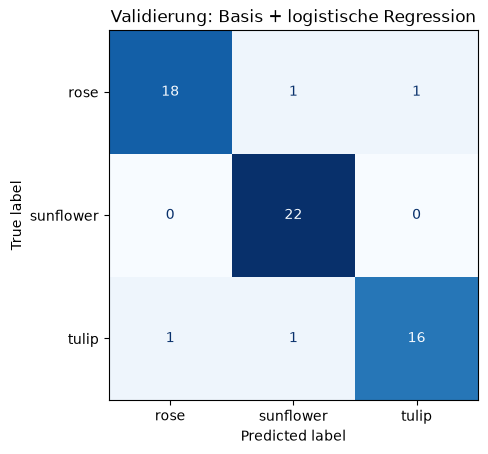

In [40]:
cm_val = show_confusion(y_val, val_probs[best_name], f"Validierung: {best_name}")

**Was wir sehen:** Auf der Validierung liegt das gewählte Modell bei 4 von 60 Fotos daneben: 2 Rosen (eine als Tulpe, eine
als Sonnenblume) und 2 Tulpen (eine als Rose, eine als Sonnenblume). Alle 22 Sonnenblumen sind richtig.

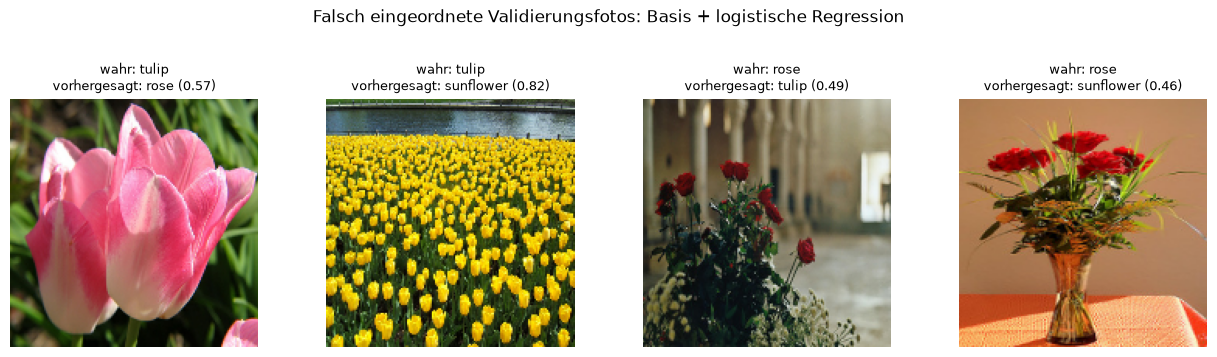

In [41]:
_ = show_errors(X_val, y_val, val_probs[best_name], f"Falsch eingeordnete Validierungsfotos: {best_name}")

**Was wir sehen:** Die vier Fehler: eine rosa Tulpe in Nahaufnahme (als Rose, 0,57), ein Feld **gelber** Tulpen (als
Sonnenblume, 0,82), rote Rosen vor einem Gebäude, klein im Bild (als Tulpe, 0,49), und ein Rosenstrauß in einer Vase mit
viel Grün (als Sonnenblume, 0,46). Drei der vier Fehler haben eine Wahrscheinlichkeit unter 0,6; das Modell ist dort
unsicher. Der sichere Fehler ist das gelbe Tulpenfeld: Farbe und Feld-Motiv sprechen für Sonnenblume.

In [42]:
threshold_table(y_val, val_probs[best_name]).round(3)

,zum Personal,Anteil zum Personal,Fehler gesamt,Fehler abgefangen
Schwelle,,,,
0.60,8,0.133,4,3
0.70,15,0.250,4,3
0.80,21,0.350,4,3
0.90,39,0.650,4,4
0.95,54,0.900,4,4


**Was wir sehen:** Die Regel „Personal prüft unter 0,8“ würde auf der Validierung **21 von 60** Fotos (35 %) zum Personal
schicken und **3 der 4** Fehler abfangen. Der vierte Fehler (gelbe Tulpen, 0,82) liegt knapp darüber. Das gewählte Modell ist
stark regularisiert und gibt deshalb vorsichtige Wahrscheinlichkeiten: Auch viele richtige Fotos liegen unter 0,8. Diese
Kosten der Regel prüfen wir in Schritt 8 auf dem Test.

### Methode einfrieren

Ab hier ändern wir nichts mehr an Modellen, Auswahl oder Regeln. Festgehalten:

- **Gewähltes Modell:** das Modell aus der Zelle „Modellwahl“ (Variable `best_name`).
- **Den Test sehen alle sieben Modelle** der Tabelle: Zufall, CNN von Grund auf, logistische Regression, Dense-Kopf,
  Augmentation, Fine-Tuning, Keras Tuner. Der Test entscheidet **nicht** neu, welches Modell das beste ist; er schätzt nur,
  wie gut die Modelle auf neuen Fotos sind.
- **Personal-Regel:** Schwelle 0,8 für die höchste Wahrscheinlichkeit, wie in der Aufgabe vorgeschlagen.
- **Falls kein Modell die Baselines schlägt:** Wir berichten das so, empfehlen dem Gartencenter, weiter jedes Foto von Hand
  einzuordnen, und wählen kein anderes Modell nach dem Testergebnis.

**Probelauf der Testauswertung.** Die Funktion `score_all` macht in Schritt 8 genau eine Sache: alle Modelle auf einem
Satz Fotos auswerten. Wir lassen sie hier auf den Validierungsfotos laufen, um Laufzeit und Code zu prüfen. Das Ergebnis
ist zugleich die Validierungsspalte der Schlusstabelle.

In [43]:
def score_all(X, y):
    probs = {n: predict_proba(n, X) for n in names}
    acc = {n: accuracy_score(y, p.argmax(1)) for n, p in probs.items()}
    return probs, acc


t = time.time()
val_probs, val_accs = score_all(X_val, y_val)
print(f"Probelauf auf {len(y_val)} Validierungsfotos: {time.time() - t:.1f} s")
pd.Series(val_accs, name="val").round(3).to_frame()

Probelauf auf 60 Validierungsfotos: 3.2 s


,val
Zufall (häufigste Klasse),0.300
Basis + logistische Regression,0.933
CNN von Grund auf (GAP),0.833
Basis + Dense-Kopf,0.917
Dense-Kopf + Augmentation,0.950
Fine-Tuning (finetune_top10_lr1e-05),0.950
Keras Tuner (Kopf),0.950


**Was wir sehen:** Der Probelauf von `score_all` auf den 60 Validierungsfotos dauert wenige Sekunden und läuft ohne
Fehler. Die Validierungsgenauigkeiten sind dieselben wie in der Modellwahl: Zufall 0,300, logistische Regression 0,933,
CNN 0,833, Dense-Kopf 0,917, Augmentation, Fine-Tuning und Tuner je 0,950. Damit ist die Testauswertung vorbereitet.

## Schritt 8: TESTZUGRIFF

**Was:** Jetzt, und nur hier, laden wir `data/test`: mit derselben `image_size`, mit `shuffle=False` (die Reihenfolge
bleibt fest und passt zu `test_ds.file_paths`) und holen Bilder und Labels in **einer** Schleife. Dann bewertet `score_all`
alle sieben Modelle auf denselben 30 Fotos. Diese Zelle läuft genau einmal; danach ändern wir nichts mehr an Modellen
oder Auswahl.

**Verworfen:** die Testfotos schon früher zu laden, etwa um die Bildgrößen zu prüfen. Jeder Blick auf den Test, der eine
Entscheidung beeinflusst, macht die Testgenauigkeit optimistisch.

In [44]:
test_ds = keras.utils.image_dataset_from_directory(DATA / "test", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
assert test_ds.class_names == class_names
X_test, y_test = collect(test_ds)
test_paths = test_ds.file_paths
test_probs, test_accs = score_all(X_test, y_test)
print("Testfotos je Klasse:", dict(zip(class_names, np.bincount(y_test).tolist())))

Found 30 files belonging to 3 classes.


Testfotos je Klasse: {'rose': 10, 'sunflower': 10, 'tulip': 10}


**Was wir sehen:** Keras findet 30 Testfotos in 3 Klassen, **10 je Klasse**, wie in der Datenbeschreibung angegeben. Die
Klassennamen stimmen mit denen des Trainings überein (die `assert`-Zeile wäre sonst abgebrochen). Alle sieben Modelle sind
auf denselben 30 Fotos bewertet.

### Die Tabelle aller Modelle

**Was:** Eine Zeile je Modell mit Parametern (gesamt und trainierbar), Validierungs- und Testgenauigkeit, dazu die Zahl
richtiger Testfotos. **Warum die Zahl der Fotos:** Bei 30 Testfotos ändert ein Foto die Genauigkeit um 3,3 Prozentpunkte;
„27 von 30“ macht das greifbarer als „0,900“. Die Abbildung stellt Validierung und Test nebeneinander.

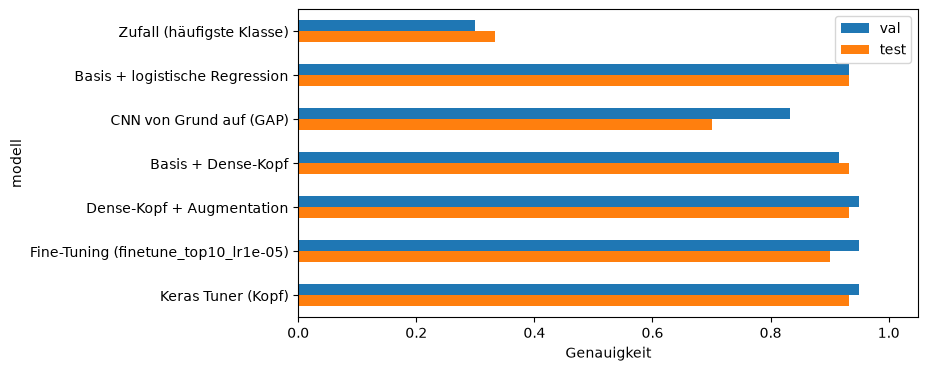

Gewähltes Modell (auf der Validierung): Basis + logistische Regression


,parameter_gesamt,parameter_trainierbar,val,test,test_richtig
modell,,,,,
Zufall (häufigste Klasse),<NA>,<NA>,0.300,0.333,10
Basis + logistische Regression,2261827,3843,0.933,0.933,28
CNN von Grund auf (GAP),23779,23779,0.833,0.700,21
Basis + Dense-Kopf,2261827,3843,0.917,0.933,28
Dense-Kopf + Augmentation,2261827,3843,0.950,0.933,28
Fine-Tuning (finetune_top10_lr1e-05),2261827,729283,0.950,0.900,27
Keras Tuner (Kopf),2422339,164355,0.950,0.933,28


In [45]:
table = pd.DataFrame([{"modell": n, "parameter_gesamt": param_info[n][0], "parameter_trainierbar": param_info[n][1],
                       "val": val_accs[n], "test": test_accs[n],
                       "test_richtig": int((test_probs[n].argmax(1) == y_test).sum())} for n in names]).set_index("modell")
ax = table[["val", "test"]].plot.barh(figsize=(8, 4), color=["tab:blue", "tab:orange"])
ax.set(xlabel="Genauigkeit", xlim=(0, 1.05))
ax.invert_yaxis()
plt.show()
print("Gewähltes Modell (auf der Validierung):", best_name)
table.astype({"parameter_gesamt": "Int64", "parameter_trainierbar": "Int64"}).round(3)

**Was wir sehen:**

- **Zufall** trifft 10 von 30 (0,333), wie erwartet genau ein Drittel.
- Der **CNN von Grund auf** fällt von 0,833 auf der Validierung auf **0,700** im Test (21 von 30).
- **Alle fünf Modelle mit vortrainierter Basis** liegen im Test bei **0,900 bis 0,933** (27 oder 28 von 30). Logistische
  Regression, Dense-Kopf, Augmentation und Keras Tuner treffen je 28, Fine-Tuning 27.
- Das **gewählte Modell** (logistische Regression) erreicht 0,933 auf der Validierung und **0,933** im Test.

**Was jede Stufe gebracht hat:** Der Schritt vom CNN zur vortrainierten Basis bringt im Test **+23 Prozentpunkte** (7 Fotos).
Augmentation, Fine-Tuning und Keras Tuner bringen im Test **nichts** (gleich viele oder ein Foto weniger). Auf der
Validierung sah es nach zwei Fotos Gewinn aus; das war im Rahmen des Rauschens. Die Parameter zeigen den Preis: Fine-Tuning
trainiert 729 283 Gewichte, der Tuner-Kopf 164 355, die logistische Regression 3 843, bei gleichem Ergebnis.

### Wie sicher sind die Unterschiede? Gepaarter Vergleich

**Was:** Alle Modelle sahen dieselben 30 Fotos. Statt zwei einzelne Intervalle zu vergleichen, schauen wir je Foto, ob das
gewählte Modell und das Vergleichsmodell richtig lagen, und ziehen 10 000-mal 30 Fotos mit Zurücklegen (Bootstrap). Das
95-%-Intervall der Differenz zeigt, ob der Vorsprung über das Rauschen der 30 Fotos hinausgeht. **Verworfen:** nur die
Punktwerte vergleichen; zwei Modelle, die bei 30 Fotos um ein Foto auseinanderliegen, sind praktisch gleich gut.

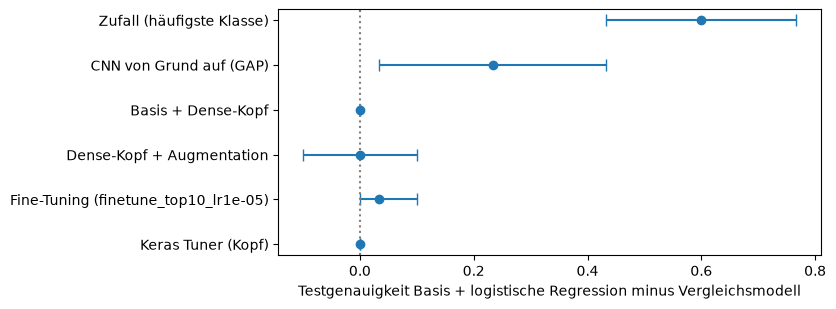

,Differenz,unten,oben
vergleich,,,
Zufall (häufigste Klasse),0.600,0.433,0.767
CNN von Grund auf (GAP),0.233,0.033,0.433
Basis + Dense-Kopf,0.000,0.000,0.000
Dense-Kopf + Augmentation,0.000,-0.100,0.100
Fine-Tuning (finetune_top10_lr1e-05),0.033,0.000,0.100
Keras Tuner (Kopf),0.000,0.000,0.000


In [46]:
def paired_ci(a, b, y, n_boot=10_000):
    """Bootstrap interval of the accuracy difference a − b on the same photos."""
    d = (a.argmax(1) == y).astype(float) - (b.argmax(1) == y).astype(float)
    idx = np.random.default_rng(SEED).integers(0, len(y), (n_boot, len(y)))
    boot = d[idx].mean(1)
    return d.mean(), *np.percentile(boot, [2.5, 97.5])


pairs = pd.DataFrame([dict(zip(["Differenz", "unten", "oben"], paired_ci(test_probs[best_name], test_probs[n], y_test)),
                           vergleich=n) for n in names if n != best_name]).set_index("vergleich")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(pairs["Differenz"], range(len(pairs)), xerr=[pairs["Differenz"] - pairs["unten"], pairs["oben"] - pairs["Differenz"]],
            fmt="o", capsize=4)
ax.axvline(0, color="grey", ls=":")
ax.set(yticks=range(len(pairs)), yticklabels=pairs.index, xlabel=f"Testgenauigkeit {best_name} minus Vergleichsmodell")
ax.invert_yaxis()
plt.show()
pairs.round(3)

**Was wir sehen:** Gegen **Zufall** gewinnt das gewählte Modell 60 Prozentpunkte, Intervall [+0,433; +0,767]; gegen den
**CNN** 23 Prozentpunkte, Intervall [+0,033; +0,433]. Beide Intervalle liegen ganz über 0, der Vorsprung ist also mehr als
Rauschen, beim CNN aber nur knapp (die untere Grenze entspricht einem Foto). Gegen **Dense-Kopf** und **Keras Tuner** ist
die Differenz genau 0 mit Intervall [0; 0]: Diese Modelle liegen bei genau denselben Fotos richtig und falsch. Gegen
**Augmentation** ist sie ebenfalls 0, aber mit Intervall [−0,10; +0,10]: Beide machen zwei Fehler, aber bei anderen Fotos.
Zwischen den Modellen mit vortrainierter Basis kann der Test keinen Unterschied auflösen.

### Erfolgskriterium aus Schritt 1

**Was:** Wir prüfen die drei Bedingungen genau im Wortlaut von Schritt 1, ohne nachträgliche Anpassung.

In [47]:
cnn_name = names[2]
crit = pd.DataFrame([
    {"Bedingung": "K1: schlägt Zufall (Intervall > 0)", "Wert": f"[{pairs.loc[names[0], 'unten']:+.3f}, {pairs.loc[names[0], 'oben']:+.3f}]",
     "erfüllt": pairs.loc[names[0], "unten"] > 0},
    {"Bedingung": "K2: schlägt CNN von Grund auf (Intervall > 0)",
     "Wert": f"[{pairs.loc[cnn_name, 'unten']:+.3f}, {pairs.loc[cnn_name, 'oben']:+.3f}]", "erfüllt": pairs.loc[cnn_name, "unten"] > 0},
    {"Bedingung": f"K3: Testgenauigkeit ≥ {SUCCESS_MIN_ACC}", "Wert": f"{test_accs[best_name]:.3f}",
     "erfüllt": test_accs[best_name] >= SUCCESS_MIN_ACC}]).set_index("Bedingung")
crit

,Wert,erfüllt
Bedingung,,
K1: schlägt Zufall (Intervall > 0),"[+0.433, +0.767]",True
K2: schlägt CNN von Grund auf (Intervall > 0),"[+0.033, +0.433]",True
K3: Testgenauigkeit ≥ 0.9,0.933,True


**Was wir sehen:** Alle drei Bedingungen sind erfüllt: K1 mit Intervall [+0,433; +0,767], K2 mit [+0,033; +0,433], K3 mit
0,933 ≥ 0,90. **Bindend** ist K2: Seine untere Grenze liegt nur ein Foto über 0, und auch K3 hält nur mit einem Foto Abstand
(28 statt mindestens 27 richtig). Ein weiterer Fehler auf dem Test hätte K3 noch erfüllt, zwei nicht.

**Einordnung:** Das Erfolgskriterium ist erfüllt, aber knapp. „Erfüllt“ heißt: Das Modell ist klar besser als Raten und als
ein CNN von Grund auf und traf auf diesen 30 Fotos mindestens 90 %. Es heißt nicht, dass es auf neuen Fotos sicher 90 %
erreicht (siehe erwartete Güte unten).

### Wo liegt das beste Modell daneben? 1. Konfusionsmatrix

**Was:** Zeilen sind die wahren Blumen, Spalten die Vorhersagen; auf der Diagonale stehen die richtig eingeordneten Fotos.
Daneben die Genauigkeit je Klasse mit der Zahl der Fotos (n = 10 je Klasse) und, zum Vergleich, die der Zufallsbaseline.

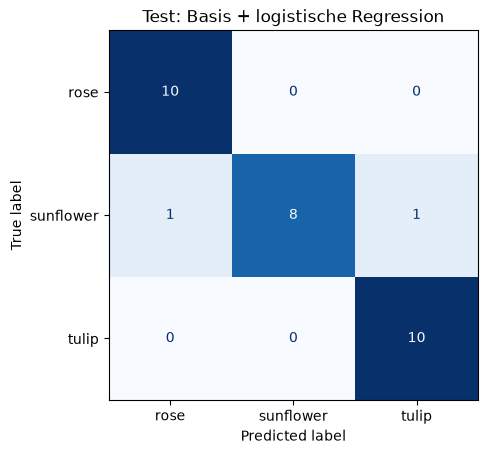

,n,richtig,Genauigkeit,Zufall
rose,10,10,1.0,0.0
sunflower,10,8,0.8,0.0
tulip,10,10,1.0,1.0


In [48]:
cm_test = show_confusion(y_test, test_probs[best_name], f"Test: {best_name}")
per_class = pd.DataFrame({"n": np.bincount(y_test), "richtig": np.diag(cm_test),
                          "Genauigkeit": np.diag(cm_test) / np.bincount(y_test),
                          "Zufall": [(test_probs[names[0]].argmax(1)[y_test == k] == k).mean() for k in range(3)]},
                         index=class_names)
per_class.round(2)

**Was wir sehen:** Alle 10 Rosen und alle 10 Tulpen sind richtig. Von den 10 Sonnenblumen sind **8** richtig, eine wurde als
Rose, eine als Tulpe eingeordnet. Die Zufallsbaseline trifft nur Tulpen (1,0) und sonst nichts. Das ist **nicht** das in
Schritt 4 erwartete Paar Rose/Tulpe; auf der Validierung kamen Verwechslungen zwischen Rose und Tulpe dagegen vor. Mit zwei
Fehlern im Test lässt sich kein Muster je Klasse belegen: 8 von 10 und 10 von 10 sind bei n = 10 nicht sicher verschieden.

### 2. Alle falsch eingeordneten Testfotos

**Was:** Jedes Testfoto, das das gewählte Modell falsch einordnet, mit wahrer Klasse, Vorhersage und der Wahrscheinlichkeit
der Vorhersage. Jedes Foto wird zusätzlich als PNG nach `abgabe/fehler/` geschrieben.

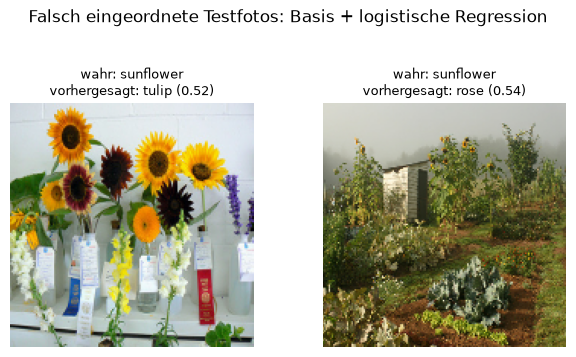

,datei,wahr,vorhergesagt,p_rose,p_sunflower,p_tulip
0,2733109082_1351f6738a_n.jpg,sunflower,tulip,0.065,0.411,0.524
1,2807106374_f422b5f00c.jpg,sunflower,rose,0.539,0.380,0.081


In [49]:
wrong_test = show_errors(X_test, y_test, test_probs[best_name], f"Falsch eingeordnete Testfotos: {best_name}",
                         save_dir=OUT / "fehler", paths=test_paths)
pd.DataFrame([{"datei": Path(test_paths[i]).name, "wahr": class_names[y_test[i]],
               "vorhergesagt": class_names[test_probs[best_name][i].argmax()],
               **{f"p_{c}": test_probs[best_name][i, k] for k, c in enumerate(class_names)}} for i in wrong_test]).round(3)

**Was wir sehen:** Die beiden falsch eingeordneten Testfotos:

1. `2733109082_1351f6738a_n.jpg`: Sonnenblumen auf einer **Blumenausstellung**, in Vasen zwischen anderen Blumen und
   Preisschleifen. Vorhergesagt Tulpe mit **0,52**, Sonnenblume 0,41.
2. `2807106374_f422b5f00c.jpg`: ein **Gemüsegarten** mit Schuppen und Kohl, die Sonnenblumen stehen klein im Hintergrund.
   Vorhergesagt Rose mit **0,54**, Tulpe 0,08, Sonnenblume 0,38.

**Gemeinsam:** Die Sonnenblume ist nicht das Hauptmotiv, das Foto zeigt viel anderes. Beide Fehler fallen mit einer
Wahrscheinlichkeit knapp über 0,5, das Modell war also unsicher. **Vermutung** (nicht belegt): Die Merkmale der Basis werden
über das ganze Bild gemittelt (`pooling="avg"`); nimmt die Blume nur einen kleinen Teil ein, bestimmt der Rest des Bildes
die Merkmale.

**Wie ähnlich sind die Testfotos dem Training?** Dieselbe Prüfung wie in Schritt 6 (Kosinus-Ähnlichkeit der Merkmale),
jetzt Test gegen Training und Validierung, und die Fotografen aus `LICENSE.txt`. Wir prüfen, ob die Fehler bei Fotos
passieren, die dem Training wenig ähneln.

In [50]:
F_test = extractor.predict(X_test, verbose=0)
sim_test = (unit(F_test) @ unit(np.vstack([F_train, F_val])).T).max(1)
dev_phot = {photographer[Path(p).name] for p in train_ds.file_paths + val_ds.file_paths}
test_phot = [lic.get(Path(p).name, "unbekannt") for p in test_paths]
correct_test = test_probs[best_name].argmax(1) == y_test
print("Testfotos mit Fotograf auch in data/train:", sum(p in dev_phot for p in test_phot), "von", len(test_phot))
print(f"Testfotos mit Ähnlichkeit > {NEAR_DUP} zu einem Foto aus data/train:", int((sim_test > NEAR_DUP).sum()))
pd.DataFrame({"richtig": correct_test, "max. Ähnlichkeit": sim_test}).groupby("richtig")["max. Ähnlichkeit"].describe().round(3)

Testfotos mit Fotograf auch in data/train: 7 von 30
Testfotos mit Ähnlichkeit > 0.9 zu einem Foto aus data/train: 0


,count,mean,std,min,25%,50%,75%,max
richtig,,,,,,,,
False,2.0,0.575,0.027,0.556,0.565,0.575,0.584,0.594
True,28.0,0.623,0.078,0.485,0.564,0.627,0.675,0.754


**Was wir sehen:** Nur **7 von 30** Testfotos haben einen Fotografen, der auch in `data/train` vorkommt (in der Validierung
waren es 39 von 60), und **kein** Testfoto ist einem Trainingsfoto fast gleich (Ähnlichkeit höchstens 0,754). Der Test ist
also unabhängiger von den Trainingsdaten als die Validierung, und trotzdem erreicht das Modell dort dieselbe Genauigkeit.
Die beiden Fehler haben Ähnlichkeiten von 0,556 und 0,594, die richtigen Fotos im Mittel 0,623 (von 0,485 bis 0,754). Die
Fehler liegen eher im unteren Bereich, aber richtig eingeordnete Fotos gibt es auch darunter: Die Ähnlichkeit zum Training
allein trennt Fehler nicht von Treffern.

### 3. Die Wahrscheinlichkeiten

**Was:** Sind falsche Vorhersagen unsicherer als richtige? Links die höchste Wahrscheinlichkeit je Testfoto, getrennt nach
richtig und falsch; rechts, wie viele Fotos eine Regel „das Personal prüft jedes Foto unter Schwelle s“ an das Personal gibt
und wie viele Fehler sie abfängt. Als **Sensitivitätsprüfung** zeigen wir mehrere Schwellen statt nur 0,8, auf Validierung
und Test.

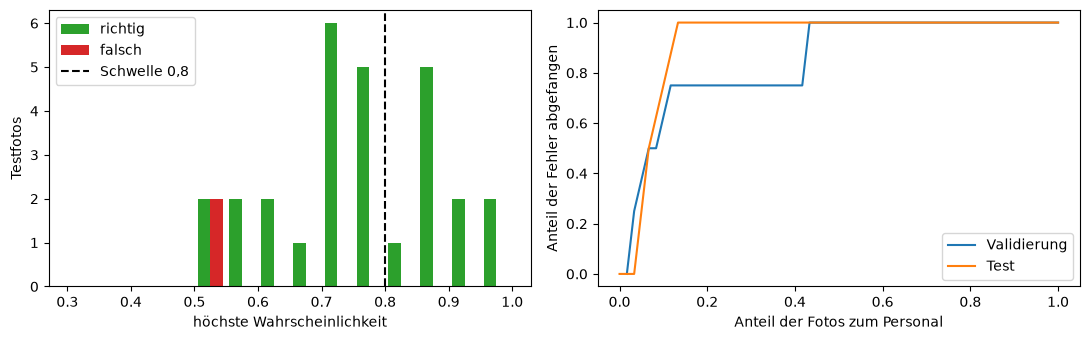

Validierung                                                      \
         zum Personal Anteil zum Personal Fehler gesamt Fehler abgefangen   
Schwelle                                                                    
0.60                8               0.133             4                 3   
0.70               15               0.250             4                 3   
0.80               21               0.350             4                 3   
0.90               39               0.650             4                 4   
0.95               54               0.900             4                 4   

                 Test                                                      
         zum Personal Anteil zum Personal Fehler gesamt Fehler abgefangen  
Schwelle                                                                   
0.60                6               0.200             2                 2  
0.70                9               0.300             2                 2  
0.80               20               0.667             2                 2  
0.90               26               0.867             2                 2  
0.95               28               0.933             2                 2

In [51]:
p_max = test_probs[best_name].max(1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist([p_max[correct_test], p_max[~correct_test]], bins=np.linspace(0.3, 1, 15), label=["richtig", "falsch"],
             color=["tab:green", "tab:red"])
axes[0].axvline(STAFF_THRESHOLD, color="black", ls="--", label="Schwelle 0,8")
axes[0].set(xlabel="höchste Wahrscheinlichkeit", ylabel="Testfotos")
axes[0].legend()
grid = np.linspace(0.4, 1.0, 61)
for y_, pr, lab in ((y_val, val_probs[best_name], "Validierung"), (y_test, test_probs[best_name], "Test")):
    pm, ok = pr.max(1), pr.argmax(1) == y_
    axes[1].plot([(pm < s).mean() for s in grid], [(~ok & (pm < s)).sum() / max((~ok).sum(), 1) for s in grid], label=lab)
axes[1].set(xlabel="Anteil der Fotos zum Personal", ylabel="Anteil der Fehler abgefangen")
axes[1].legend()
plt.tight_layout()
plt.show()
pd.concat({"Validierung": threshold_table(y_val, val_probs[best_name]), "Test": threshold_table(y_test, test_probs[best_name])},
          axis=1).round(3)

**Was wir sehen:** Beide Fehler liegen links im Histogramm (0,52 und 0,54), bei den niedrigsten Wahrscheinlichkeiten.
Richtige Vorhersagen streuen aber breit von 0,5 bis 0,97, viele liegen zwischen 0,7 und 0,8. Die Regel **„Personal prüft
unter 0,8“** fängt im Test **beide** Fehler ab, schickt aber **20 von 30** Fotos (67 %) zum Personal; auf der Validierung
waren es 21 von 60 (35 %) bei 3 von 4 abgefangenen Fehlern. Ein Grund: Das gewählte Modell ist stark regularisiert und gibt
**vorsichtige** Wahrscheinlichkeiten; bei den Testfotos, die dem Training weniger ähneln, ist es noch vorsichtiger.

**Sensitivität der Schwelle:** Bei 0,6 gingen im Test 6 von 30 Fotos (20 %) zum Personal und beide Fehler würden abgefangen;
auf der Validierung 8 von 60 (13 %) mit 3 von 4 Fehlern. Die rechte Grafik zeigt: Mit etwa 15 bis 45 % der Fotos beim
Personal fängt die Regel auf beiden Teilen die meisten oder alle Fehler. Die Schwelle wählen wir aber **nicht** nach dem
Test (er ist nur zum Messen da). Die Regel funktioniert also im Prinzip: Fehler kommen mit niedriger Wahrscheinlichkeit.
Wie viel Arbeit sie macht, hängt stark von der Schwelle ab und sollte mit neuen Fotos eingestellt werden.

### Ist die Validierungsgenauigkeit des Keras-Tuner-Modells fair?

**Was:** Der Tuner hat 10 Köpfe auf denselben 60 Validierungsfotos verglichen und den besten behalten. Der beste von zehn
ist auch dann oft besser als die anderen, wenn alle gleich gut sind, schlicht durch Glück mit diesen 60 Fotos. Seine
Validierungsgenauigkeit ist deshalb **zu optimistisch**; dasselbe gilt schwächer für jede Auswahl auf der Validierung
(Fine-Tuning-Variante, `EarlyStopping`, Modellwahl). Die Tabelle stellt für die drei auf der Validierung ausgewählten
Modelle Validierung und Test gegenüber.

In [52]:
sel_models = [n for n in names if n.startswith(("Keras Tuner", "Fine-Tuning"))] + [best_name]
gap = table.loc[list(dict.fromkeys(sel_models)), ["val", "test"]]
gap["val − test"] = gap["val"] - gap["test"]
gap.round(3)

,val,test,val − test
modell,,,
Fine-Tuning (finetune_top10_lr1e-05),0.950,0.900,0.050
Keras Tuner (Kopf),0.950,0.933,0.017
Basis + logistische Regression,0.933,0.933,0.000


**Was wir sehen:** Der Tuner-Kopf erreicht 0,950 auf der Validierung und 0,933 im Test; die gewählte Fine-Tuning-Variante
0,950 und 0,900; die logistische Regression 0,933 und 0,933. Die Modelle, die als bestes aus vielen Varianten auf der
Validierung herausgesucht wurden (10 Tuner-Versuche, 6 Fine-Tuning-Varianten), verlieren im Test am meisten, die
logistische Regression (C in der Kreuzvalidierung nur auf dem Training gewählt) nichts. Das passt zur Erwartung: **Die
Validierungsgenauigkeit des Tuner-Modells ist zu optimistisch.** Beweisen lässt es sich mit diesen Zahlen nicht: Die
Unterschiede betragen ein bis zwei Fotos.

### Erwartete Güte auf neuen Fotos

**Was:** Wie genau wird das Modell auf neuen Fotos derselben Art sein? **Punktschätzung:** die Testgenauigkeit, ohne
Aufschlag, denn nur der Test war an keiner Entscheidung beteiligt. **Bereich:** das exakte 95-%-Binomialintervall
(Clopper-Pearson, aus `scipy.stats.binomtest`) für 30 Fotos. Es fragt: Welche wahren Genauigkeiten passen zu dem, was wir
auf 30 Fotos gesehen haben? **Verworfen:** die Validierungsgenauigkeit als Schätzung (sie wurde zur Auswahl benutzt, also
optimistisch) und ein Intervall aus Validierung und Test zusammen (aus demselben Grund). Eine Kreuzvalidierung der
Keras-Modelle, die eine Streuung über Folds liefern würde, haben wir aus Zeitgründen nicht gerechnet.

Zum Vergleich steht das Intervall der Validierung daneben; überlappen sich beide gut, ist die Schätzung stimmig.

In [53]:
k_test = int(correct_test.sum())
ci_test = stats.binomtest(k_test, len(y_test)).proportion_ci(method="exact")
k_val = int((val_probs[best_name].argmax(1) == y_val).sum())
ci_val = stats.binomtest(k_val, len(y_val)).proportion_ci(method="exact")
expect = pd.DataFrame({"richtig": [k_test, k_val], "n": [len(y_test), len(y_val)],
                       "Genauigkeit": [k_test / len(y_test), k_val / len(y_val)],
                       "95 % unten": [ci_test.low, ci_val.low], "95 % oben": [ci_test.high, ci_val.high]},
                      index=["Test (Schätzung)", "Validierung (optimistisch)"])
expect.round(3)

,richtig,n,Genauigkeit,95 % unten,95 % oben
Test (Schätzung),28,30,0.933,0.779,0.992
Validierung (optimistisch),56,60,0.933,0.838,0.982


**Was wir sehen:** Im Test 28 von 30 richtig, **0,933**; das exakte 95-%-Intervall reicht von **0,779 bis 0,992**. Die
Validierung (56 von 60, 0,933, Intervall 0,838 bis 0,982) liegt mitten darin; beide Schätzungen passen zusammen. **Erwartete
Güte auf neuen Fotos derselben Art: etwa 93 %, mit hoher Wahrscheinlichkeit zwischen 78 % und 99 %.** Der Bereich ist breit,
weil 30 Fotos wenig sind; mehr Testfotos würden ihn schmaler machen, nicht das Modell besser.

### Ergebnisse speichern

**Was:** `ergebnis.json` im Format des Auftrags, aus den Variablen dieses Notebooks geschrieben (keine abgeschriebenen
Zahlen). Die Fehlerfotos liegen schon in `abgabe/fehler/`.

In [54]:
ergebnis = {
    "metrik": "accuracy",
    "bildgroesse": list(IMG_SIZE),
    "bestes_modell": best_name,
    "tabelle": [{"modell": n, "parameter_gesamt": param_info[n][0], "parameter_trainierbar": param_info[n][1],
                 "val": round(float(val_accs[n]), 4), "test": round(float(test_accs[n]), 4)} for n in names],
    "konfusion_test": cm_test.tolist(),
    "klassen": class_names,
    "erwartete_guete": {
        "accuracy": round(k_test / len(y_test), 4),
        "intervall": [round(float(ci_test.low), 4), round(float(ci_test.high), 4)],
        "begruendung": (f"Punkt = Testgenauigkeit des auf der Validierung gewählten Modells ({k_test}/{len(y_test)} Fotos, "
                        "ohne Aufschlag), Bereich = exaktes 95-%-Binomialintervall für 30 Testfotos; die Validierung "
                        "diente der Auswahl und ist daher nicht Teil der Schätzung.")},
}
(OUT / "ergebnis.json").write_text(json.dumps(ergebnis, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Gespeichert: ergebnis.json, {len(list((OUT / 'fehler').glob('*.png')))} Fehlerfotos | "
      f"Laufzeit des Notebooks: {(time.time() - T0) / 60:.1f} min")

Gespeichert: ergebnis.json, 2 Fehlerfotos | Laufzeit des Notebooks: 11.3 min


**Was wir sehen:** `ergebnis.json` und die **2** Fehlerfotos sind in `abgabe/` gespeichert. Das ganze Notebook lief in
**11,3 Minuten**, deutlich unter dem Rahmen von 60 Minuten.

## Fazit

**Antwort auf die Frage.** Mit nur 100 Fotos je Blume erkennt eine **logistische Regression auf den Merkmalen von
MobileNetV2** (vortrainiert, eingefroren, 160 × 160) **28 von 30** Testfotos richtig (0,933). Erwartet auf neuen Fotos
derselben Art: etwa 93 %, Bereich 78 % bis 99 %.

| Stufe | Validierung | Test | Was sie gebracht hat |
|---|---|---|---|
| Zufall (immer Tulpe) | 0,300 | 0,333 | Messlatte |
| CNN von Grund auf (GAP) | 0,833 | 0,700 | lernt etwas, aber überangepasst bzw. langsam; 240 Fotos reichen nicht |
| Basis + logistische Regression (**gewählt**) | 0,933 | 0,933 | **der große Sprung: +23 Punkte im Test gegen den CNN** |
| Basis + Dense-Kopf | 0,917 | 0,933 | gleich gut wie die logistische Regression |
| + Augmentation | 0,950 | 0,933 | auf der Validierung zwei Fotos mehr, im Test nichts |
| + Fine-Tuning (oberste 10 Schichten, lr 1e-5) | 0,950 | 0,900 | nichts Messbares |
| Keras Tuner (Kopf 128 Neuronen, Dropout 0,4) | 0,950 | 0,933 | bessere Wahrscheinlichkeiten auf der Validierung, gleiche Treffer |

Der Gewinn kommt fast ganz aus dem **Vortraining**: Ein Netz, das auf ImageNet gelernt hat, Formen und Texturen zu
erkennen, liefert Merkmale, auf denen schon ein linearer Kopf die drei Blumen trennt. Augmentation, Fine-Tuning und
Tuner verbessern das bei 240 Trainingsfotos nicht nachweisbar; dafür sind sie aufwendiger. Deshalb hat die Auswahlregel
das einfachste Modell gewählt.

**Wo es danebenliegt:** Im Test bei zwei Sonnenblumenfotos, auf denen die Sonnenblume nicht das Hauptmotiv ist
(Blumenausstellung mit vielen Blumenarten, Gemüsegarten mit Sonnenblumen im Hintergrund). Auf der Validierung zusätzlich bei
Rose gegen Tulpe (rosa Tulpe in Nahaufnahme, kleine rote Rosen) und bei einem Feld gelber Tulpen. Fast alle Fehler kommen
mit einer Wahrscheinlichkeit unter 0,6.

**Grenzen.** 30 Testfotos lassen nur große Unterschiede erkennen. Die Validierung ist leicht optimistisch: 2 der 60
Validierungsfotos haben einen fast identischen Zwilling im Training, 39 von 60 teilen den Fotografen mit Trainingsfotos.
Der Split von `image_dataset_from_directory` kann das nicht verhindern. Auf der CPU sind die Läufe nicht bitgleich
reproduzierbar (hier ergaben drei Läufe vor dem Test dieselben Zahlen, garantiert ist das nicht).

**Was man als Nächstes versuchen würde:** mehr Fotos sammeln, besonders schwierige (Sträuße, Gärten, gelbe Tulpen); die
Personal-Schwelle mit neuen, eigenen Fotos des Gartencenters einstellen; die Wahrscheinlichkeiten kalibrieren (etwa weniger
strenge Regularisierung oder Platt-Skalierung); eine Klasse „keine dieser Blumen“ oder eine Ablehnungsregel für fremde
Blumen; Fotos zuschneiden, sodass die Blume den größten Teil des Bildes füllt.

### Wann man dem Modell nicht trauen sollte

- **Andere Blumen.** Das Modell kennt nur drei Klassen. Ein Gänseblümchen oder eine Dahlie bekommt trotzdem eine der drei
  Anleitungen. Die Website muss sagen, welche Blumen der Dienst abdeckt.
- **Die Blume ist nicht das Hauptmotiv.** Gärten, Beete mit vielen Pflanzenarten, Ausstellungen, gemischte Sträuße: Genau
  dort lagen die Fehler.
- **Gelbe oder rosa Tulpen, rosa Rosen in Nahaufnahme.** Die Farbe führt hier in die Irre (Validierungsfehler).
- **Fotos ohne Blüte** (nur Blätter, Knospen, Rosenstrauch im Winter): Solche Fotos gibt es im Training praktisch nicht.
- **Wahrscheinlichkeit unter etwa 0,6 bis 0,8:** Diese Fotos sollte das Personal prüfen; die genaue Schwelle mit eigenen
  Fotos festlegen.
- **Fotos, die anders aussehen als die Flickr-Fotos** (Handyfotos mit anderem Licht, sehr kleine oder stark beschnittene
  Bilder): Die Trainingsfotos sind 159 bis 640 Pixel breit und meist gut belichtet.

**Hinweise an den Auftraggeber (Datenlieferung):** In `data/train` sind 2 Validierungsfotos (nach dem Split mit Seed 42)
fast identisch mit einem Trainingsfoto (Ähnlichkeit über 0,90); im Test gibt es keine solchen Paare. Ein Fotograf
(liz west) stellt 32 der 300 Trainingsfotos. Es gibt keine byte-gleichen Dubletten, keine unlesbaren Dateien, alle Fotos sind
RGB. Entscheidung: nichts gelöscht, die Optimismus-Folge oben benannt.